<font size="6" color="blue">Module 8 – Clustering and Unsupervised Learning</font>

<img src="module8_images/00_mod8.png" width="600"/>


Although most of the applications of Machine Learning today are based on supervised learning, the vast majority of the available data is unlabeled: **we have the input features X , but we do not have the labels y.** 

Unsupervised learning is used to extract the inherent patterns in a dataset without seeing any labels. In the last module we looked at the most common unsupervised learning task: dimensionality reduction. 

In this module we will look at a few more unsupervised learning tasks and algorithms: 
- **Clustering:** The goal is to group similar instances together into clusters . Clustering is a great tool for data analysis, customer segmentation, recommender systems, search engines, image segmentation, semi-supervised learning, dimensionality reduction, and more. 
- **Anomaly detection:** The objective is to learn what “normal” data looks like, and then use that to detect abnormal instances, such as defective items on a production line or a new trend in a time series. 
- **Density estimation:** This is the task of estimating the probability density function (PDF) of the random process that generated the dataset. Density estimation is commonly used for anomaly detection: instances located in very low-density regions are likely to be anomalies. It is also useful for data analysis and visualization. 

We will start with clustering, using K-Means and DBSCAN, and then we will discuss Gaussian mixture models and see how they can be used for density estimation, clustering, and anomaly detection. 

**SETUP**

In [1]:
# Common imports
import numpy as np
import pandas as pd
import os

# Plotly imports
import matplotlib.pyplot as plt
import plotly.graph_objects as go
import numpy as np

# to make this notebook's output stable across runs
np.random.seed(42)

# To plot pretty figures
%matplotlib inline
import matplotlib as mpl
import matplotlib.pyplot as plt
mpl.rc('axes', labelsize=14)
mpl.rc('xtick', labelsize=12)
mpl.rc('ytick', labelsize=12)

# Clustering

As you enjoy a hike in the mountains: 
- You stumble upon a plant you have never seen before. 
- You look around and you notice a few more. 
- They are not identical, yet they are sufficiently similar for you to know that they most likely belong to the same species (or at least the same genus). 

You may need a botanist to tell you what species that is, but you certainly don’t need an expert to identify groups of similar-looking objects. **This is called clustering:** 
- It is the task of identifying similar instances and assigning them to clusters , or groups of similar instances. 


## Introduction – Classification _vs_ Clustering

Just like in classification, each instance gets assigned to a group. 

However, unlike classification, clustering is an unsupervised task. 

Consider the chart below: 
- the left is the iris dataset, where each instance’s species (i.e., its class) is represented with a different marker. 
- It is a labeled dataset, for which classification algorithms such as Logistic Regression, SVMs, or Random Forest classifiers are well suited. 
- On the right is the same dataset, but without the labels, so you cannot use a classification algorithm anymore. This is where clustering algorithms step in: 
    - many of them can easily detect the lower-left cluster. It is also quite easy to see with our own eyes, but it is not so obvious that the upper-right cluster is composed of two distinct sub-clusters. 
    - That said, the dataset has two additional features (sepal length and width), not represented here, and clustering algorithms can make good use of all features, so in fact they identify the three clusters fairly well (e.g., using a Gaussian mixture model, only 5 instances out of 150 are assigned to the wrong cluster). 

In [2]:
from sklearn.datasets import load_iris

In [3]:
data = load_iris()
X = data.data
y = data.target
data.target_names

array(['setosa', 'versicolor', 'virginica'], dtype='<U10')

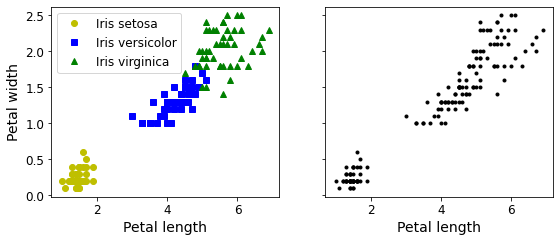

In [4]:
plt.figure(figsize=(9, 3.5))

plt.subplot(121)
plt.plot(X[y==0, 2], X[y==0, 3], "yo", label="Iris setosa")
plt.plot(X[y==1, 2], X[y==1, 3], "bs", label="Iris versicolor")
plt.plot(X[y==2, 2], X[y==2, 3], "g^", label="Iris virginica")
plt.xlabel("Petal length", fontsize=14)
plt.ylabel("Petal width", fontsize=14)
plt.legend(fontsize=12)

plt.subplot(122)
plt.scatter(X[:, 2], X[:, 3], c="k", marker=".")
plt.xlabel("Petal length", fontsize=14)
plt.tick_params(labelleft=False)

plt.show()

A Gaussian mixture model (explained later on) can actually separate these clusters pretty well (using all 4 features: petal length & width, and sepal length & width).

In [5]:
from sklearn.mixture import GaussianMixture

In [6]:
y_pred = GaussianMixture(n_components=3, random_state=42).fit(X).predict(X)
mapping = np.array([1, 2, 0])
y_pred = np.array([mapping[cluster_id] for cluster_id in y_pred])

y_pred[0:100]

array([2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0])

In [7]:
y[0:100]

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1])

In [8]:
sum(y_pred==y)/len(y)

0.03333333333333333

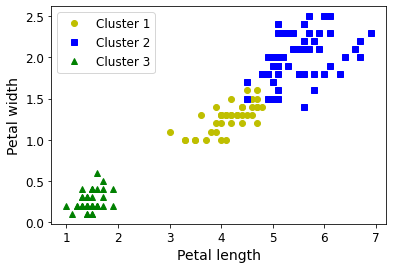

In [9]:
plt.plot(X[y_pred==0, 2], X[y_pred==0, 3], "yo", label="Cluster 1")
plt.plot(X[y_pred==1, 2], X[y_pred==1, 3], "bs", label="Cluster 2")
plt.plot(X[y_pred==2, 2], X[y_pred==2, 3], "g^", label="Cluster 3")
plt.xlabel("Petal length", fontsize=14)
plt.ylabel("Petal width", fontsize=14)
plt.legend(loc="upper left", fontsize=12)
plt.show()

Clustering is used in a wide variety of applications, including:
- **Customer segmentation:**
    - You can cluster your customers based on their purchases and their activity on your website. This is useful to understand who your customers are and what they need, so you can adapt your products and marketing campaigns to each segment. 
- **Data analysis:** 
    - When you analyze a new dataset, it can be helpful to run a clustering algorithm, and then analyze each cluster separately. 
- **Dimensionality reduction:** 
    - Once a dataset has been clustered, it is usually possible to measure each instance’s affinity with each cluster (affinity is any measure of how well an instance fits into a cluster). 
    - **Each instance’s feature vector x can then be replaced with the vector of its cluster affinities.** If there are k clusters, then this vector is k dimensional. This vector is typically much lower-dimensional than the original feature vector, but it can preserve enough information for further processing. 
- **Anomaly detection (also called outlier detection):**
    - Any instance that has a low affinity to all the clusters is likely to be an anomaly. Anomaly detection is particularly useful in detecting defects in manufacturing, or for fraud detection. 
- **Semi-supervised learning:** 
    - If you only have a few labels, you could perform clustering and **propagate the labels to all the instances in the same cluster**. 
    - This technique can **greatly increase the number of labels available for a subsequent supervised learning algorithm**, and thus improve its performance. 
- **Search engines:** 
    - Some search engines let you search for images that are similar to a reference image. 
    - To build such a system, you would first apply a clustering algorithm to all the images in your database; similar images would end up in the same cluster. 
    - Then when a user provides a reference image, all you need to do is use the trained clustering model to find this image’s cluster, and you can then simply return all the images from this cluster. 
    
There is no universal definition of what a cluster is: 
- It really depends on the context, and different algorithms will capture different kinds of clusters. 
- Some algorithms look for instances centered around a particular point, called a centroid. 
- Others look for continuous regions of densely packed instances: these clusters can take on any shape. 
- Some algorithms are hierarchical, looking for clusters of clusters. And the list goes on. 

In this section, we will look at two popular clustering algorithms, **K-Means** and **DBSCAN**, and explore some of their applications, such as nonlinear dimensionality reduction, semi-supervised learning, and anomaly detection.

## K-Means

Consider the unlabeled dataset created below: 
- you can clearly see five blobs of instances. 
- The K-Means algorithm is a simple algorithm capable of clustering this kind of dataset very quickly and efficiently, often in just a few iterations. 


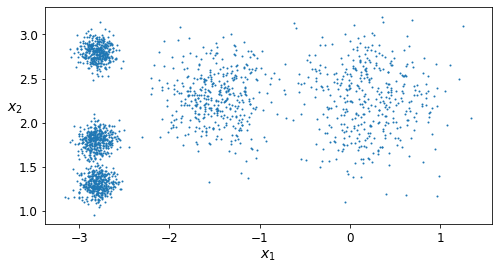

In [10]:
from sklearn.datasets import make_blobs
blob_centers = np.array(
    [[ 0.2,  2.3],
     [-1.5 ,  2.3],
     [-2.8,  1.8],
     [-2.8,  2.8],
     [-2.8,  1.3]])
blob_std = np.array([0.4, 0.3, 0.1, 0.1, 0.1])

X, y = make_blobs(n_samples=2000, centers=blob_centers,
                  cluster_std=blob_std, random_state=7)

def plot_clusters(X, y=None):
    plt.scatter(X[:, 0], X[:, 1], c=y, s=1)
    plt.xlabel("$x_1$", fontsize=14)
    plt.ylabel("$x_2$", fontsize=14, rotation=0)
    
    
plt.figure(figsize=(8, 4))
plot_clusters(X)
plt.show()

### Fit and Predict

Let's train a K-Means clusterer on this dataset. It will try to find each blob's center and assign each instance to the closest blob:


Note that you have to specify the **number of clusters `k`** that the algorithm must find. 

In this example, it is pretty obvious from looking at the data that k should be set to 5, but **in general it is not that easy**. We will discuss this shortly. 


In [11]:
from sklearn.cluster import KMeans

In [12]:
k = 5
kmeans = KMeans(n_clusters=k, random_state=42)
kmeans.fit(X)

KMeans(n_clusters=5, random_state=42)

Each instance was assigned to one of the 5 clusters:

In [13]:
y_pred = kmeans.predict(X)
# Could also use fit_predict
np.unique(y_pred)

array([0, 1, 2, 3, 4], dtype=int32)

In [14]:
all(y_pred == kmeans.labels_)

True

And the following 5 _centroids_ (i.e., cluster centers) were estimated:

In [15]:
clusters = kmeans.cluster_centers_
clusters

array([[-2.80389616,  1.80117999],
       [ 0.20876306,  2.25551336],
       [-2.79290307,  2.79641063],
       [-1.46679593,  2.28585348],
       [-2.80037642,  1.30082566]])

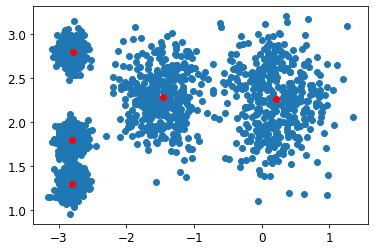

In [16]:
k = 5
kmeans = KMeans(n_clusters=k, random_state=42)
kmeans.fit(X)
clusters = kmeans.cluster_centers_
plt.scatter(X[:,0],X[:,1])
plt.scatter(clusters[:,0],clusters[:,1], c='r')
plt.show()

Each instance was assigned to one of the five clusters. 

In the context of clustering, **an instance’s label is the index of the cluster** that this instance gets assigned to by the algorithm: 
- this is not to be confused with the class labels in classification (remember that clustering is an unsupervised learning task). 
- The KMeans instance preserves a copy of the labels of the instances it was trained on, available via the `labels_` instance variable: 

In [17]:
kmeans.labels_

array([4, 0, 1, ..., 2, 1, 0], dtype=int32)

Of course, we can predict the labels of new instances:

In [18]:
X_new = np.array([[0, 2], [3, 2], [-3, 3], [-3, 2.5]])
kmeans.predict(X_new)

array([1, 1, 2, 2], dtype=int32)

### Decision Boundaries

Let's plot the model's decision boundaries. This gives us a _Voronoi diagram_:

In [142]:
def plot_data(X):
    plt.plot(X[:, 0], X[:, 1], 'k.', markersize=2)

def plot_centroids(centroids, weights=None, circle_color='w', cross_color='k'):
    if weights is not None:
        centroids = centroids[weights > weights.max() / 10]
    plt.scatter(centroids[:, 0], centroids[:, 1],
                marker='o', s=3, linewidths=10,
                color=circle_color, zorder=10, alpha=0.9)
    plt.scatter(centroids[:, 0], centroids[:, 1],
                marker='x', s=1, linewidths=10,
                color=cross_color, zorder=11, alpha=1)

def plot_decision_boundaries(clusterer, X, resolution=1000, show_centroids=True,
                             show_xlabels=True, show_ylabels=True):
    mins = X.min(axis=0) - 0.1
    maxs = X.max(axis=0) + 0.1
    xx, yy = np.meshgrid(np.linspace(mins[0], maxs[0], resolution),
                         np.linspace(mins[1], maxs[1], resolution))
    Z = clusterer.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    plt.contourf(Z, extent=(mins[0], maxs[0], mins[1], maxs[1]),
                cmap="Pastel2")
    plt.contour(Z, extent=(mins[0], maxs[0], mins[1], maxs[1]),
                linewidths=1, colors='k')
    plot_data(X)
    if show_centroids:
        plot_centroids(clusterer.cluster_centers_)

    if show_xlabels:
        plt.xlabel("$x_1$", fontsize=14)
    else:
        plt.tick_params(labelbottom=False)
    if show_ylabels:
        plt.ylabel("$x_2$", fontsize=14, rotation=0)
    else:
        plt.tick_params(labelleft=False)

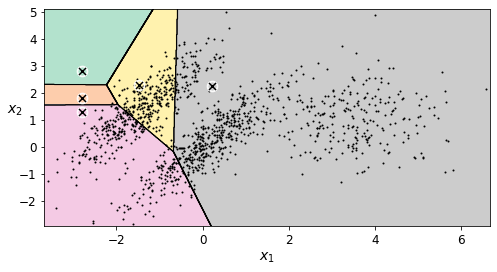

In [143]:
plt.figure(figsize=(8, 4))
plot_decision_boundaries(kmeans, X)
plt.show()

Not bad! Some of the instances near the edges were probably assigned to the wrong cluster, but overall it looks pretty good.

### Hard Clustering _vs_ Soft Clustering

The vast majority of the instances were clearly assigned to the appropriate cluster, but a few instances were probably mislabeled (especially near the boundary between the top-left cluster and the central cluster). 

The K-Means algorithm **does not behave very well when the blobs have very different diameters because all it cares about when assigning an instance to a cluster is the distance to the centroid.** 
- Instead of assigning each instance to a single cluster, which is called **hard clustering**, it can be useful to give each instance a score per cluster, which is called **soft clustering**.
- The score can be the distance between the instance and the centroid.
- It can also be a similarity score (or affinity), such as the **Gaussian Radial Basis Function**. 


In the KMeans class, the `transform()` method measures the distance from each instance to every centroid: 

In [34]:
kmeans.transform(X_new)

array([[2.81093633, 0.32995317, 2.9042344 , 1.49439034, 2.88633901],
       [5.80730058, 2.80290755, 5.84739223, 4.4759332 , 5.84236351],
       [1.21475352, 3.29399768, 0.29040966, 1.69136631, 1.71086031],
       [0.72581411, 3.21806371, 0.36159148, 1.54808703, 1.21567622]])

You can verify that this is indeed the Euclidian distance between each instance and each centroid:

In [35]:
X_tiled = np.tile(X_new, (1, k)).reshape(-1, k, 2)
# X_tiled
np.linalg.norm(X_tiled - kmeans.cluster_centers_, axis=2)

array([[2.81093633, 0.32995317, 2.9042344 , 1.49439034, 2.88633901],
       [5.80730058, 2.80290755, 5.84739223, 4.4759332 , 5.84236351],
       [1.21475352, 3.29399768, 0.29040966, 1.69136631, 1.71086031],
       [0.72581411, 3.21806371, 0.36159148, 1.54808703, 1.21567622]])

### K-Means Algorithm

The K-Means algorithm is one of the fastest clustering algorithms, but also one of the simplest:
* First initialize $k$ centroids randomly: $k$ distinct instances are chosen randomly from the dataset and the centroids are placed at their locations.
* Repeat following steps until convergence (i.e., until the centroids stop moving):
    * Assign each instance to the closest centroid.
    * Update the centroids to be the mean of the instances that are assigned to them.
    
    
<img src="module8_images/01_kmeans.gif" width="500"/>


The `KMeans` class applies an optimized algorithm by default.

To get the _original_ K-Means algorithm (for educational purposes only), you must set `init="random"`, `n_init=1`and `algorithm="full"`. These hyperparameters will be explained below.

Let's run the K-Means algorithm for 1, 2 and 3 iterations, to see how the centroids move around:

In [36]:
kmeans_iter1 = KMeans(n_clusters=5, init="random", n_init=1, algorithm="full", max_iter=1, random_state=1)
kmeans_iter2 = KMeans(n_clusters=5, init="random", n_init=1, algorithm="full", max_iter=2, random_state=1)
kmeans_iter3 = KMeans(n_clusters=5, init="random", n_init=1, algorithm="full", max_iter=3, random_state=1)
kmeans_iter1.fit(X)
kmeans_iter2.fit(X)
kmeans_iter3.fit(X)

KMeans(algorithm='full', init='random', max_iter=3, n_clusters=5, n_init=1,
       random_state=1)

And let's plot this:

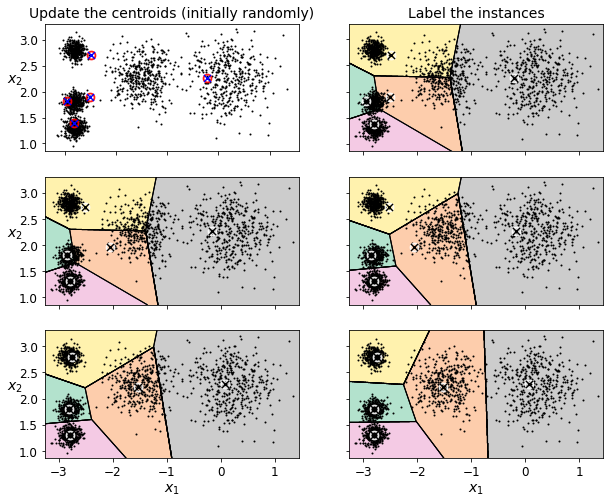

In [123]:
plt.figure(figsize=(10, 8))

plt.subplot(321)
plot_data(X)
plot_centroids(kmeans_iter1.cluster_centers_, circle_color='r', cross_color='b')
plt.ylabel("$x_2$", fontsize=14, rotation=0)
plt.tick_params(labelbottom=False)
plt.title("Update the centroids (initially randomly)", fontsize=14)

plt.subplot(322)
plot_decision_boundaries(kmeans_iter1, X, show_xlabels=False, show_ylabels=False)
plt.title("Label the instances", fontsize=14)

plt.subplot(323)
plot_decision_boundaries(kmeans_iter1, X, show_centroids=False, show_xlabels=False)
plot_centroids(kmeans_iter2.cluster_centers_)

plt.subplot(324)
plot_decision_boundaries(kmeans_iter2, X, show_xlabels=False, show_ylabels=False)

plt.subplot(325)
plot_decision_boundaries(kmeans_iter2, X, show_centroids=False)
plot_centroids(kmeans_iter3.cluster_centers_)

plt.subplot(326)
plot_decision_boundaries(kmeans_iter3, X, show_ylabels=False)

plt.show()

Although the algorithm is **guaranteed to converge, it may not converge to the right solution (i.e., it may converge to a local optimum):** 
- whether it does or not depends on the **centroid initialization**. 
- The algorithm can produce suboptimal solutions if you are not **lucky with the random initialization step**. 

### K-Means Variability

In the original K-Means algorithm, the centroids are just initialized randomly, and the algorithm simply runs a single iteration to gradually improve the centroids, as we saw above.

One major problem with this approach is that if you run K-Means multiple times (or with different random seeds), it can **converge to very different solutions:**

In [61]:
def plot_clusterer_comparison(clusterer1, clusterer2, X, title1=None, title2=None):
    clusterer1.fit(X)
    clusterer2.fit(X)

    plt.figure(figsize=(10, 3.2))

    plt.subplot(121)
    plot_decision_boundaries(clusterer1, X)
    if title1:
        plt.title(title1, fontsize=14)

    plt.subplot(122)
    plot_decision_boundaries(clusterer2, X, show_ylabels=False)
    if title2:
        plt.title(title2, fontsize=14)

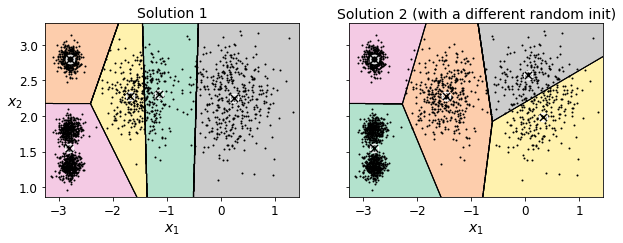

In [124]:
kmeans_rnd_init1 = KMeans(n_clusters=5, init="random", n_init=1,
                         algorithm="full", random_state=50)
kmeans_rnd_init2 = KMeans(n_clusters=5, init="random", n_init=1,
                         algorithm="full", random_state=100)

plot_clusterer_comparison(kmeans_rnd_init1, kmeans_rnd_init2, X,
                          "Solution 1", "Solution 2 (with a different random init)")

plt.show()

### Inertia

To select the best model, we will need a way to evaluate a K-Mean model's performance. 

- Clustering is an unsupervised task, so **we do not have the targets**, and thus we cannot use metrics like MSE or Logloss.

- Instead, we can measure the distance between each instance and its centroid. 

- This is the idea behind the _inertia_ metric:

In [89]:
kmeans.inertia_

211.59853725816836

Inertia is the **sum of the squared distances** between each training instance and its closest centroid:

In [90]:
X_dist = kmeans.transform(X)
np.sum(X_dist[np.arange(len(X_dist)), kmeans.labels_]**2)

211.59853725816856

The `score()` method returns the negative inertia. 

Why negative? Well, it is because a predictor's `score()` method must always respect the "_great is better_" rule: 
- if a predictor is better than another, its `score()` method should return a greater score. 

In [91]:
kmeans.score(X)

-211.5985372581684

### Multiple Initializations

So one approach to solve the variability issue is to simply run the K-Means algorithm multiple times with different random initializations, and select the solution that **minimizes the inertia.**

For example, here are the inertias of the two "bad" models shown in the previous figure:

In [92]:
print(kmeans_rnd_init1.inertia_)
kmeans_rnd_init1.score(X)

236.7984812375912


-236.7984812375912

In [93]:
print(kmeans_rnd_init2.inertia_)
kmeans_rnd_init2.score(X)

219.43539442771402


-219.43539442771402

In [94]:
print(kmeans.inertia_)
kmeans.score(X)

211.59853725816836


-211.5985372581684

As you can see, they have a higher inertia (lower score) than the first "good" model we trained, which means they are probably worse.

When you set the `n_init` hyperparameter, Scikit-Learn runs the original algorithm `n_init` times, and selects the solution that minimizes the inertia:
-   `n_init`:  Number of time the k-means algorithm will be run with different centroid seeds. The final results will be the **best output of n_init consecutive runs in terms of inertia**.

By default, Scikit-Learn sets `n_init=10`.

In [95]:
kmeans_rnd_10_inits = KMeans(n_clusters=5, init="random", n_init=10,
                              algorithm="full", random_state=11)
kmeans_rnd_10_inits.fit(X)

KMeans(algorithm='full', init='random', n_clusters=5, random_state=11)

As you can see, we end up with the initial model, which is certainly the optimal K-Means solution (at least in terms of inertia, and assuming $k=5$).

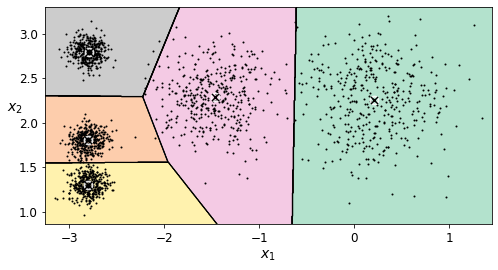

In [125]:
plt.figure(figsize=(8, 4))
plot_decision_boundaries(kmeans_rnd_10_inits, X)
plt.show()

### K-Means++

Instead of initializing the centroids entirely randomly, it is preferable to initialize them using the following algorithm, proposed in a [2006 paper](https://goo.gl/eNUPw6) by David Arthur and Sergei Vassilvitskii:
* Take one centroid $c_1$, chosen uniformly at random from the dataset.
* Take a new center $c_i$, choosing an instance $\mathbf{x}_i$ with probability: $D(\mathbf{x}_i)^2$ / $\sum\limits_{j=1}^{m}{D(\mathbf{x}_j)}^2$ where $D(\mathbf{x}_i)$ is the distance between the instance $\mathbf{x}_i$ and the closest centroid that was already chosen. 
* This probability distribution ensures that **instances that are further away from already chosen centroids are much more likely be selected as centroids.**
* Repeat the previous step until all $k$ centroids have been chosen.

The rest of the K-Means++ algorithm is just regular K-Means:
- With this initialization, the K-Means algorithm is much less likely to converge to a suboptimal solution

- With this change we can also reduce `n_init` considerably (this is makes it worth the additional computational complexity of computing $c_i$ probabilities).

- Most of the time, this largely compensates for the additional complexity of the initialization process.

To set the initialization to K-Means++, simply set `init="k-means++"` (this is actually the default):

In [99]:
kmeans = KMeans(n_clusters=5, init="k-means++", n_init=2, random_state=42)
kmeans.fit(X)
kmeans.inertia_

211.5985372581684

In [100]:
good_init = np.array([[-3, 3], [-3, 2], [-3, 1], [-1, 2], [0, 2]])
kmeans = KMeans(n_clusters=5, init=good_init, n_init=1, random_state=42)
kmeans.fit(X)
kmeans.inertia_

211.59853725816836

### Accelerated K-Means

The K-Means algorithm can be significantly accelerated by avoiding many unnecessary distance calculations: 
- this is achieved by exploiting the **triangle inequality** (given three points A, B and C, the distance AC is always such that AC ≤ AB + BC) and by **keeping track of lower and upper bounds for distances between instances and centroids** 
- (see this [2003 paper](https://www.aaai.org/Papers/ICML/2003/ICML03-022.pdf) by **Charles Elkan** for more details).

This is the algorithm the KMeans class uses by default (you can force it to use the original algorithm by setting the algorithm hyperparameter to "full" , although you probably will never need to). 

To use Elkan's variant of K-Means, just set `algorithm="elkan"`.
- Note that it does not support sparse data, so by default, Scikit-Learn uses `"elkan"` for dense data, and `"full"` (the regular K-Means algorithm) for sparse data.

In [101]:
%timeit -n 50 KMeans(algorithm="auto").fit(X) # Accelerated K-Means

72.5 ms ± 1.9 ms per loop (mean ± std. dev. of 7 runs, 50 loops each)


In [102]:
%timeit -n 50 KMeans(algorithm="elkan").fit(X) # Accelerated K-Means

71.8 ms ± 1.72 ms per loop (mean ± std. dev. of 7 runs, 50 loops each)


In [103]:
%timeit -n 50 KMeans(algorithm="full").fit(X) # Regular K-Means

81.7 ms ± 3.29 ms per loop (mean ± std. dev. of 7 runs, 50 loops each)


### Mini-Batch K-Means

Yet another important variant of the K-Means algorithm was proposed in a 2010 paper by David Sculley:

- Instead of using the full dataset at each iteration, the algorithm is capable of using mini-batches, **moving the centroids just slightly at each iteration**. 

- This speeds up the algorithm typically by **a factor of three or four** and makes it possible to cluster huge datasets that do not fit in memory. 

Scikit-Learn implements this algorithm in the MiniBatchKMeans class. You can just use this class like the KMeans class: 

In [104]:
from sklearn.cluster import MiniBatchKMeans

In [105]:
minibatch_kmeans = MiniBatchKMeans(n_clusters=5, random_state=42)
minibatch_kmeans.fit(X)

MiniBatchKMeans(n_clusters=5, random_state=42)

In [106]:
minibatch_kmeans.inertia_

211.652398504332

If the dataset does not fit in memory, the simplest option is to use the `memmap` class, just like we did for incremental PCA in the previous module. First let's load MNIST:

In [107]:
import urllib
from sklearn.datasets import fetch_openml

mnist = fetch_openml('mnist_784', version=1)
mnist.target = mnist.target.astype(np.int64)

In [108]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    mnist["data"], mnist["target"], random_state=42)

Next, let's write it to a `memmap`:

In [112]:
filename = "my_mnist.data"
X_mm = np.memmap(filename, dtype='float32', mode='write', shape=X_train.shape)
X_mm[:] = X_train

In [113]:
minibatch_kmeans = MiniBatchKMeans(n_clusters=10, batch_size=10, random_state=42)
minibatch_kmeans.fit(X_mm)

MiniBatchKMeans(batch_size=10, n_clusters=10, random_state=42)

If your data is so large that you cannot use `memmap`, things get more complicated. We will need to use the `partial_fit` method.  

Let's start by writing a function to load the next batch (in real life, you would load the data from disk):

In [114]:
def load_next_batch(batch_size):
    return X[np.random.choice(len(X), batch_size, replace=False)]

Now we can train the model by feeding it one batch at a time. 

We also need to implement multiple initializations and keep the model with the lowest inertia:

In [115]:
np.random.seed(42)

In [116]:
k = 5
n_init = 10
n_iterations = 100
batch_size = 100
init_size = 500  # more data for K-Means++ initialization
evaluate_on_last_n_iters = 10

best_kmeans = None

for init in range(n_init):
    minibatch_kmeans = MiniBatchKMeans(n_clusters=k, init_size=init_size)
    X_init = load_next_batch(init_size)
    minibatch_kmeans.partial_fit(X_init)

    minibatch_kmeans.sum_inertia_ = 0
    for iteration in range(n_iterations):
        X_batch = load_next_batch(batch_size)
        minibatch_kmeans.partial_fit(X_batch)
        if iteration >= n_iterations - evaluate_on_last_n_iters:
            minibatch_kmeans.sum_inertia_ += minibatch_kmeans.inertia_

    if (best_kmeans is None or minibatch_kmeans.sum_inertia_ < best_kmeans.sum_inertia_):
        best_kmeans = minibatch_kmeans

In [117]:
best_kmeans.score(X)

-211.62571878891143

Mini-batch K-Means is much faster than regular K-Means:

In [118]:
%timeit KMeans(n_clusters=5).fit(X)

42.9 ms ± 2.28 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)


In [119]:
%timeit MiniBatchKMeans(n_clusters=5).fit(X)

25 ms ± 578 µs per loop (mean ± std. dev. of 7 runs, 10 loops each)


Although the Mini-batch K-Means algorithm is much faster than the regular K-Means algorithm, its inertia is generally slightly worse, especially as the number of clusters increases:
- the plot on the left compares the inertias of Mini-batch K-Means and regular K-Means models trained on the previous dataset using various numbers of clusters k . 
- The difference between the two curves remains fairly constant, but this difference becomes more and more significant as k increases, since the inertia becomes smaller and smaller. 
- In the plot on the right, you can see that Mini-batch K-Means is much faster than regular K-Means, and this difference increases with k . 

**DO NOT RUN: This will take around 8-10 minutes**

In [ ]:
from timeit import timeit
times = np.empty((100, 2))
inertias = np.empty((100, 2))
for k in range(1, 101):
    kmeans_ = KMeans(n_clusters=k, random_state=42)
    minibatch_kmeans = MiniBatchKMeans(n_clusters=k, random_state=42)
    print("\r{}/{}".format(k, 100), end="")
    times[k-1, 0] = timeit("kmeans_.fit(X)", number=10, globals=globals())
    times[k-1, 1]  = timeit("minibatch_kmeans.fit(X)", number=10, globals=globals())
    inertias[k-1, 0] = kmeans_.inertia_
    inertias[k-1, 1] = minibatch_kmeans.inertia_

100/100

Saving figure minibatch_kmeans_vs_kmeans


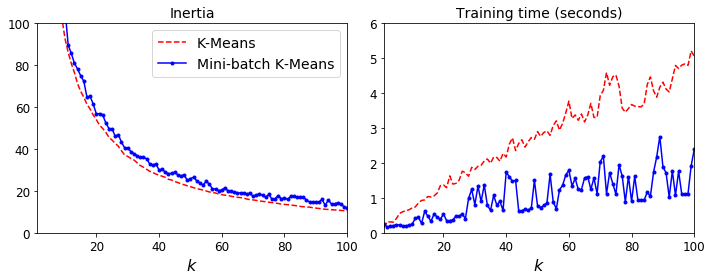

In [ ]:
plt.figure(figsize=(10,4))

plt.subplot(121)
plt.plot(range(1, 101), inertias[:, 0], "r--", label="K-Means")
plt.plot(range(1, 101), inertias[:, 1], "b.-", label="Mini-batch K-Means")
plt.xlabel("$k$", fontsize=16)
plt.title("Inertia", fontsize=14)
plt.legend(fontsize=14)
plt.axis([1, 100, 0, 100])

plt.subplot(122)
plt.plot(range(1, 101), times[:, 0], "r--", label="K-Means")
plt.plot(range(1, 101), times[:, 1], "b.-", label="Mini-batch K-Means")
plt.xlabel("$k$", fontsize=16)
plt.title("Training time (seconds)", fontsize=14)
plt.axis([1, 100, 0, 6])

save_fig("minibatch_kmeans_vs_kmeans")
plt.show()

### Finding the optimal number of clusters

So far, we have set the number of clusters k to 5 because it was obvious by looking at the data that this was the correct number of clusters. 

But in general, it will not be so easy to know how to set k , and the result might be quite bad if you set it to the wrong value: 

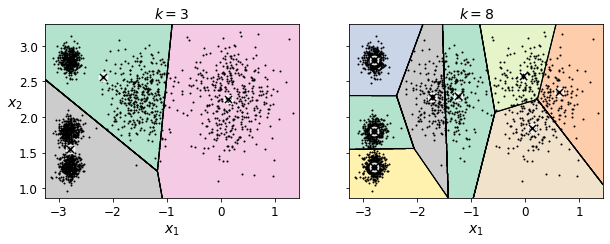

In [126]:
kmeans_k3 = KMeans(n_clusters=3, random_state=42)
kmeans_k8 = KMeans(n_clusters=8, random_state=42)

plot_clusterer_comparison(kmeans_k3, kmeans_k8, X, "$k=3$", "$k=8$")
plt.show()

In [127]:
kmeans_k3.inertia_

653.2167190021553

In [128]:
kmeans_k8.inertia_

119.11983416102879

Wait, why does `k=8` gives us such a low inertia? Doesn't a lower inertia mean = a better model?
- Unfortunately, it is not that simple. The inertia for k=3 is 653.2, which is much higher than for k=5 (which was 211.6). But with k =8, the inertia is just 119.1. 
- The inertia is not a good performance metric when trying to choose k because **it keeps getting lower as we increase k**. 

**The more clusters there are, the closer each instance will be to its closest centroid, and therefore the lower the inertia will be.** 

Let’s plot the inertia as a function of k:

In [129]:
kmeans_per_k = [KMeans(n_clusters=k, random_state=42).fit(X) for k in range(1, 10)]
inertias = [model.inertia_ for model in kmeans_per_k]

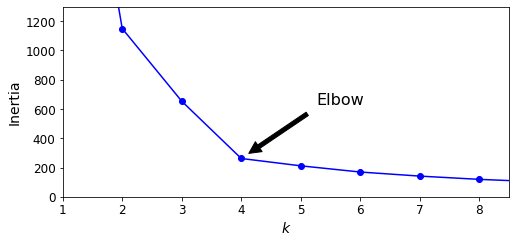

In [130]:
plt.figure(figsize=(8, 3.5))
plt.plot(range(1, 10), inertias, "bo-")
plt.xlabel("$k$", fontsize=14)
plt.ylabel("Inertia", fontsize=14)
plt.annotate('Elbow',
             xy=(4, inertias[3]),
             xytext=(0.55, 0.55),
             textcoords='figure fraction',
             fontsize=16,
             arrowprops=dict(facecolor='black', shrink=0.1)
            )
plt.axis([1, 8.5, 0, 1300])
plt.show()

As you can see, the inertia drops very quickly as we increase k up to 4, but then it decreases much more slowly as we keep increasing k:
- This curve has roughly the shape of an arm, and there is an “elbow” at k = 4. 
- If we did not know better, 4 would be a good choice: any lower value would be dramatic, while any higher value would not help much, and we might just be splitting perfectly good clusters in half for no good reason. 
- This technique for choosing the best value for the number of clusters is rather coarse. 

A more precise approach (but also more computationally expensive) is to use the **silhouette score**:
- Silhouette score is the **mean silhouette coefficient over all the instances**. 
- An instance’s silhouette coefficient is equal to $( b – a ) / max( a , b )$, 
    - $a$ is the mean distance to the other instances in the same cluster (i.e., the mean intra-cluster distance)
    - $b$ is the mean nearest-cluster distance (i.e., the mean distance to the instances of the next closest cluster, defined as the one that minimizes $b$ , excluding the instance’s own cluster). 
- The silhouette coefficient can vary between –1 and +1:
    - a coefficient close to +1 means that the instance is well inside its own cluster and far from other clusters
    - a coefficient close to 0 means that it is close to a cluster boundary
    - a coefficient close to –1 means that the instance may have been assigned to the wrong cluster

To compute the silhouette score, you can use Scikit-Learn’s `silhouette_score()` function, giving it all the instances in the dataset and the labels they were assigned: 

In [131]:
from sklearn.metrics import silhouette_score
silhouette_score(X, kmeans.labels_)

0.655517642572828

In [132]:
# Custom implementation
def silhouette_singleRow(X,kmeans_model,row):
    # if there is only one point in the cluster, there will always be silhouette value of 0?
    points_in_cluster = X[kmeans_model.labels_==kmeans_model.labels_[row]]   
    if points_in_cluster.shape[0]==1:
        return 0
    else:
        # copmute a_x
        a_x_distances=[]
        for point in range(len(points_in_cluster)):
            a_x_distances.append((np.linalg.norm(X[row] - points_in_cluster[point])))
        a_x_distances = sorted([abs(x) for x in a_x_distances])[1:] #get rid of zero from 'distance to self'
        a_x=np.mean(a_x_distances)

        # compute b_x
        all_clusters = list(range(0,max(kmeans_model.labels_+1)))
        not_row_clusters = [x for x in all_clusters if x != kmeans_model.labels_[row]] #select other clusters
        avg_distances = []
        for cluster in not_row_clusters:
            X_cluster_specific = X[kmeans_model.labels_==cluster] # select rows of specific cluster
            avg_point_distances = []
            for point in range(len(X_cluster_specific)):
                avg_point_distances.append(np.linalg.norm(X[row] - X_cluster_specific[point]))
            avg_distances.append(np.mean(avg_point_distances))
        b_x=sorted([abs(x) for x in avg_distances])[0] #take first number as it represents distance from closest cluster

        # compute s_x
        s_x = (b_x-a_x)/(max(b_x,a_x))
        return s_x

def silhouette_allRow(X,kmeans_model):
    if kmeans_model.labels_.sum() == 0:
        return "No samples... only one cluster",0
    else:
        silhouette_samps = []
        for y in range(len(X)):
            silhouette_samps.append(silhouette_singleRow(X,kmeans_model,y))
        return silhouette_samps, np.mean(silhouette_samps)

In [133]:
%time
#test to make sure custom function matches result of SKlearn function
samps, s_x = silhouette_allRow(X,kmeans)
print(s_x)

CPU times: user 2 µs, sys: 0 ns, total: 2 µs
Wall time: 5.01 µs
0.6555176425728282


In [134]:
# Calculate silhouette for multiple k values
silhouette_scores = [silhouette_score(X, model.labels_) for model in kmeans_per_k[1:]]

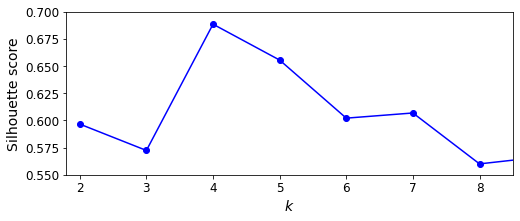

In [135]:
plt.figure(figsize=(8, 3))
plt.plot(range(2, 10), silhouette_scores, "bo-")
plt.xlabel("$k$", fontsize=14)
plt.ylabel("Silhouette score", fontsize=14)
plt.axis([1.8, 8.5, 0.55, 0.7])
plt.show()

As you can see, this visualization is much richer than the previous one: 
- although it confirms that k = 4 is a very good choice, it also underlines the fact that k = 5 is quite good as well, and much better than k = 6 or 7. 
- This was not visible when comparing inertias. 

An even more informative visualization is obtained when you plot every instance’s silhouette coefficient, sorted by the cluster they are assigned to and by the value of the coefficient. This is called a **silhouette diagram**. 
- Each diagram contains one knife shape per cluster. 
- The shape’s height indicates the number of instances the cluster contains
- Its width represents the sorted silhouette coefficients of the instances in the cluster (wider is better). 
- The dashed line indicates the mean silhouette coefficient. 

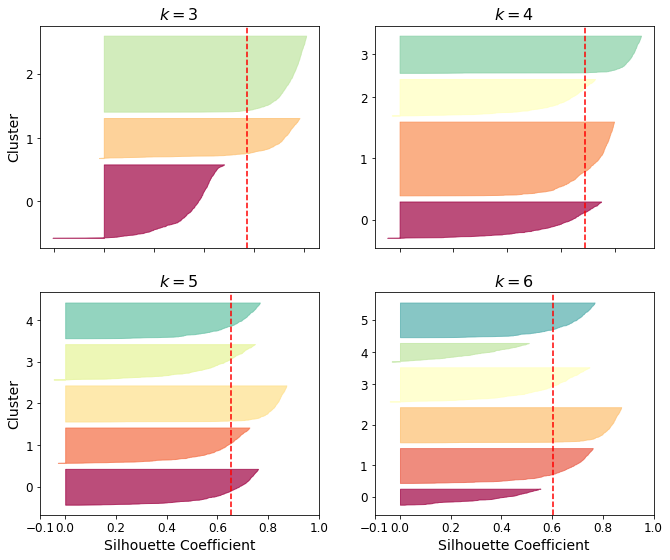

In [136]:
from sklearn.metrics import silhouette_samples
from matplotlib.ticker import FixedLocator, FixedFormatter

plt.figure(figsize=(11, 9))

for k in (3, 4, 5, 6):
    plt.subplot(2, 2, k - 2)
    
    y_pred = kmeans_per_k[k - 1].labels_
    silhouette_coefficients = silhouette_samples(X, y_pred)

    padding = len(X) // 30
    pos = padding
    ticks = []
    for i in range(k):
        coeffs = silhouette_coefficients[y_pred == i]
        coeffs.sort()

        color = mpl.cm.Spectral(i / k)
        plt.fill_betweenx(np.arange(pos, pos + len(coeffs)), 0, coeffs,
                          facecolor=color, edgecolor=color, alpha=0.7)
        ticks.append(pos + len(coeffs) // 2)
        pos += len(coeffs) + padding

    plt.gca().yaxis.set_major_locator(FixedLocator(ticks))
    plt.gca().yaxis.set_major_formatter(FixedFormatter(range(k)))
    if k in (3, 5):
        plt.ylabel("Cluster")
    
    if k in (5, 6):
        plt.gca().set_xticks([-0.1, 0, 0.2, 0.4, 0.6, 0.8, 1])
        plt.xlabel("Silhouette Coefficient")
    else:
        plt.tick_params(labelbottom=False)

    plt.axvline(x=silhouette_scores[k - 2], color="red", linestyle="--")
    plt.title("$k={}$".format(k), fontsize=16)

plt.show()

### Limits of K-Means

Despite its many merits, most notably being **fast and scalable**, K-Means is not perfect.
- It is necessary to run the algorithm several times to avoid suboptimal solutions 
- You need to specify the number of clusters, which can be quite a hassle. 
- It does not behave very well when the clusters have **varying sizes, different densities, or nonspherical shapes**. 

For example, the plot below shows how K-Means clusters a dataset containing three ellipsoidal clusters of different dimensions, densities, and orientations:

In [137]:
X1, y1 = make_blobs(n_samples=1000, centers=((4, -4), (0, 0)), random_state=42)
X1 = X1.dot(np.array([[0.374, 0.95], [0.732, 0.598]]))
X2, y2 = make_blobs(n_samples=250, centers=1, random_state=42)
X2 = X2 + [6, -8]
X = np.r_[X1, X2]
y = np.r_[y1, y2]

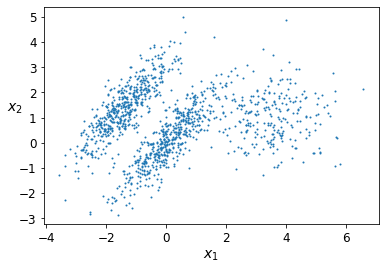

In [138]:
plot_clusters(X)

In [140]:
kmeans_good = KMeans(n_clusters=3, init=np.array([[-1.5, 2.5], [0.5, 0], [4, 0]]), n_init=1, random_state=42)
kmeans_bad = KMeans(n_clusters=3, random_state=42)
kmeans_good.fit(X)
kmeans_bad.fit(X)

KMeans(n_clusters=3, random_state=42)

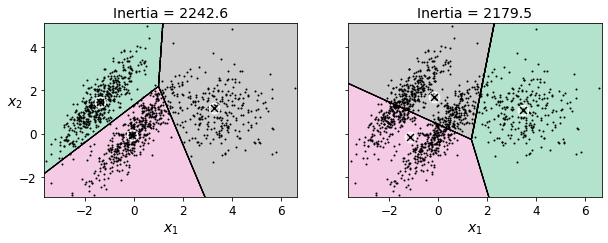

In [144]:
plt.figure(figsize=(10, 3.2))

plt.subplot(121)
plot_decision_boundaries(kmeans_good, X)
plt.title("Inertia = {:.1f}".format(kmeans_good.inertia_), fontsize=14)

plt.subplot(122)
plot_decision_boundaries(kmeans_bad, X, show_ylabels=False)
plt.title("Inertia = {:.1f}".format(kmeans_bad.inertia_), fontsize=14)

plt.show()

As you can see, neither of these solutions is any good:
- The solution on the left is better, but it still chops off 25% of the middle cluster and assigns it to the cluster on the right. 
- The solution on the right is just terrible, even though its inertia is lower. So, depending on the data, different clustering algorithms may perform better. 
- **On these types of elliptical clusters, Gaussian mixture models work great.**

**NOTE:** It is important to scale the input features before you run K-Means, or the clusters may be very stretched and K-Means will perform poorly. 
- Scaling the features does not guarantee that all the clusters will be nice and spherical, but it generally improves things. 


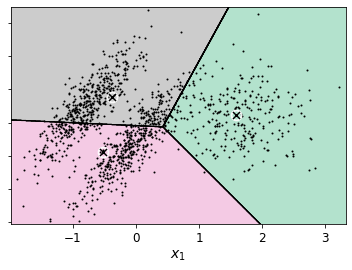

In [145]:
from sklearn.preprocessing import StandardScaler
X_scaled = StandardScaler().fit_transform(X)
km2 = KMeans(n_clusters=3).fit(X_scaled)
plot_decision_boundaries(km2, X_scaled, show_ylabels=False)

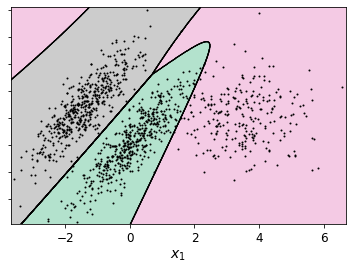

In [155]:
gm = GaussianMixture(n_components=3, random_state=20).fit(X)
        
plot_decision_boundaries(gm, X, show_ylabels=False, show_centroids=False)

### Using clustering for image segmentation

Image segmentation is the task of partitioning an image into multiple segments. 

- **Semantic segmentation:** 

    - All pixels that are part of the same object type get assigned to the same segment. 
    
    - For example, in a self-driving car’s vision system, all pixels that are part of a pedestrian’s image might be assigned to the “pedestrian” segment (there would be one segment containing all the pedestrians). 
    
    - https://blog.tensorflow.org/2019/11/updated-bodypix-2.html

- **Instance segmentation:** 
    
    - All pixels that are part of the same individual object are assigned to the same segment. 
    
    - In this case there would be a different segment for each pedestrian. 

    - The state of the art in semantic or instance segmentation today is achieved using complex architectures based on convolutional neural networks. 

Here, we are going to do something much simpler: 

- **Color segmentation:** 
    
    - We will simply assign pixels to the same segment if they have a similar color. 
    
    - In some applications, this may be sufficient. For example, if you want to analyze satellite images to measure how much total forest area there is in a region, color segmentation may be just fine. 


In [157]:
# Download the ladybug image
import urllib
images_path = os.path.join("images", "unsupervised_learning")
os.makedirs(images_path, exist_ok=True)
DOWNLOAD_ROOT = "https://raw.githubusercontent.com/ageron/handson-ml2/master/"
filename = "ladybug.png"
print("Downloading", filename)
url = DOWNLOAD_ROOT + "images/unsupervised_learning/" + filename
urllib.request.urlretrieve(url, os.path.join(images_path, filename))

('images/unsupervised_learning/ladybug.png',
 <http.client.HTTPMessage at 0x7fda45ee74f0>)

(533, 800, 3)


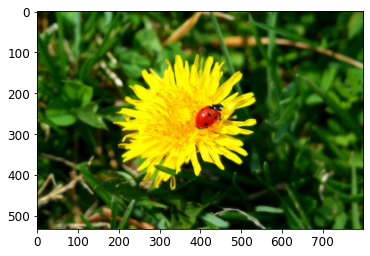

In [158]:
from matplotlib.image import imread
image = imread(os.path.join(images_path, filename)) # read in image
print(image.shape)
plt.imshow(image)

In [159]:
image[0]

array([[0.09803922, 0.11372549, 0.00784314],
       [0.09411765, 0.10980392, 0.00392157],
       [0.09411765, 0.11372549, 0.        ],
       ...,
       [0.22352941, 0.4117647 , 0.08235294],
       [0.21960784, 0.40392157, 0.08627451],
       [0.20392157, 0.3882353 , 0.07450981]], dtype=float32)

The image is represented as a **3D array:**
- The first dimension’s size is the height; 
- the second is the width; 
- and the third is the number of color channels, in this case red, green, and blue (RGB). 

In other words, for each pixel there is a **3D vector containing the intensities of red, green, and blue**, each between 0.0 and 1.0 (or between 0 and 255, if you use imageio.imread() ). 

Some images may have fewer channels, such as grayscale images (one channel). And some images may have more channels, such as images with an additional alpha channel for transparency or satellite images, which often contain channels for many light frequencies (e.g., infrared). 

The following code **reshapes the array to get a long list of RGB colors**, then it clusters these colors using K-Means: 

In [160]:
533*800

426400

In [161]:
X = image.reshape(-1, 3)
X.shape

(426400, 3)

In [162]:
kmeans = KMeans(n_clusters=8, random_state=42).fit(X)
segmented_img = kmeans.cluster_centers_[kmeans.labels_]
segmented_img = segmented_img.reshape(image.shape)

In [163]:
idx = np.random.randint(0,X.shape[0], 1000)
labels = kmeans.labels_[idx]
np.unique(labels)

array([0, 1, 2, 3, 4, 5, 6, 7], dtype=int32)

In [164]:
import plotly.graph_objects as go
import numpy as np

params = dict(size=4,color=labels,colorscale='Viridis')
fig = go.Figure(data=[go.Scatter3d(x=X[idx,0],
                                   y=X[idx,1],
                                   z=X[idx,2],
                                   mode='markers',
                                   marker=params
                                  )])

fig.show()

In [165]:
segmented_imgs = []
n_colors = (10, 8, 6, 4, 2)
for n_clusters in n_colors:
    kmeans = KMeans(n_clusters=n_clusters, random_state=42).fit(X)
    segmented_img = kmeans.cluster_centers_[kmeans.labels_]
    segmented_imgs.append(segmented_img.reshape(image.shape))

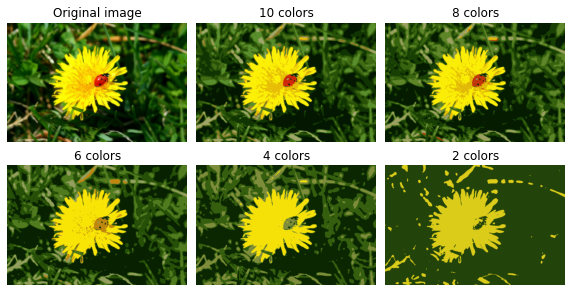

In [166]:
plt.figure(figsize=(10,5))
plt.subplots_adjust(wspace=0.05, hspace=0.1)

plt.subplot(231)
plt.imshow(image)
plt.title("Original image")
plt.axis('off')

for idx, n_clusters in enumerate(n_colors):
    plt.subplot(232 + idx)
    plt.imshow(segmented_imgs[idx])
    plt.title("{} colors".format(n_clusters))
    plt.axis('off')

plt.show()

You can experiment with various numbers of clusters, as shown above. 

When you use fewer than eight clusters, notice that the ladybug’s flashy red color fails to get a cluster of its own: 
- it gets merged with colors from the environment. 
- This is because K-Means prefers clusters of similar sizes. 
- The ladybug is small much smaller than the rest of the image so even though its color is flashy, K-Means fails to dedicate a cluster to it. 

### Using Clustering for Preprocessing

Clustering can be an efficient approach to dimensionality reduction, in particular as a **preprocessing step before a supervised learning algorithm.**

As an example of using clustering for dimensionality reduction, let’s tackle the digits dataset, which is a **simple MNIST-like dataset containing 1,797 grayscale 8 × 8 images** representing the digits 0 to 9. 

First, load the dataset: 

In [167]:
from sklearn.datasets import load_digits

In [168]:
X_digits, y_digits = load_digits(return_X_y=True)

Let's split it into a training set and a test set:

In [169]:
from sklearn.model_selection import train_test_split

In [170]:
X_train, X_test, y_train, y_test = train_test_split(X_digits, y_digits, random_state=42)
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(1347, 64)
(450, 64)
(1347,)
(450,)


Now let's fit a Logistic Regression model and evaluate it on the test set:

In [171]:
from sklearn.linear_model import LogisticRegression

In [172]:
log_reg = LogisticRegression(multi_class="ovr", solver="lbfgs", max_iter=5000, random_state=42)
log_reg.fit(X_train, y_train)

LogisticRegression(max_iter=5000, multi_class='ovr', random_state=42)

In [173]:
log_reg.score(X_test, y_test)

0.9688888888888889

Okay, that's our baseline: 96.89% accuracy. 

Let's see if we can do better by using K-Means as a preprocessing step. 

We will create a pipeline that will first cluster the training set into 50 clusters and replace the images with their distances to the 50 clusters, then apply a logistic regression model:

In [174]:
from sklearn.pipeline import Pipeline

m = KMeans(n_clusters=50, random_state=42).fit(X_train)

In [175]:
print(X_train.shape)
m.transform(X_train).shape

(1347, 64)


(1347, 50)

In [176]:
pipeline = Pipeline([
    ("kmeans", KMeans(n_clusters=50, random_state=42)),
    ("log_reg", LogisticRegression(multi_class="ovr", solver="lbfgs", max_iter=5000, random_state=42)),
])
pipeline.fit(X_train, y_train)

Pipeline(steps=[('kmeans', KMeans(n_clusters=50, random_state=42)),
                ('log_reg',
                 LogisticRegression(max_iter=5000, multi_class='ovr',
                                    random_state=42))])

In [177]:
pipeline.score(X_test, y_test)

0.9777777777777777

In [178]:
1 - (1 - 0.977777) / (1 - 0.968888)

0.28570969400874346

How about that? We reduced the error rate by over 28%, even though we used fewer features (50 instead of the original 64)! 

But we chose the number of clusters $k$ completely arbitrarily, we can surely do better:
- Since K-Means is just a preprocessing step in a classification pipeline, finding a good value for $k$ is much simpler than earlier
- There's no need to perform silhouette analysis or minimize the inertia, the best value of $k$ is simply the one that results in the best classification performance.

In [179]:
from sklearn.model_selection import GridSearchCV

**DO NOT RUN**

In [180]:
param_grid = dict(kmeans__n_clusters=range(50, 150))
param_grid

{'kmeans__n_clusters': range(50, 150)}

In [ ]:
# THIS WILL TAKE ~20 MINUTES
grid_clf = GridSearchCV(pipeline, param_grid, cv=3, verbose=2)
grid_clf.fit(X_train, y_train)

Fitting 3 folds for each of 100 candidates, totalling 300 fits
[CV] kmeans__n_clusters=50 ...........................................


[Parallel(n_jobs=1)]: Using backend SequentialBackend with 1 concurrent workers.


[CV] ............................ kmeans__n_clusters=50, total=   3.0s
[CV] kmeans__n_clusters=50 ...........................................


[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    3.0s remaining:    0.0s


[CV] ............................ kmeans__n_clusters=50, total=   3.4s
[CV] kmeans__n_clusters=50 ...........................................
[CV] ............................ kmeans__n_clusters=50, total=   3.9s
[CV] kmeans__n_clusters=51 ...........................................
[CV] ............................ kmeans__n_clusters=51, total=   4.0s
[CV] kmeans__n_clusters=51 ...........................................
[CV] ............................ kmeans__n_clusters=51, total=   3.3s
[CV] kmeans__n_clusters=51 ...........................................
[CV] ............................ kmeans__n_clusters=51, total=   3.4s
[CV] kmeans__n_clusters=52 ...........................................
[CV] ............................ kmeans__n_clusters=52, total=   3.0s
[CV] kmeans__n_clusters=52 ...........................................
[CV] ............................ kmeans__n_clusters=52, total=   3.0s
[CV] kmeans__n_clusters=52 ...........................................
[CV] .

[Parallel(n_jobs=1)]: Done 300 out of 300 | elapsed: 16.0min finished


GridSearchCV(cv=3, error_score=nan,
             estimator=Pipeline(memory=None,
                                steps=[('kmeans',
                                        KMeans(algorithm='auto', copy_x=True,
                                               init='k-means++', max_iter=300,
                                               n_clusters=50, n_init=10,
                                               n_jobs=None,
                                               precompute_distances='auto',
                                               random_state=42, tol=0.0001,
                                               verbose=0)),
                                       ('log_reg',
                                        LogisticRegression(C=1.0,
                                                           class_weight=None,
                                                           dual=False,
                                                           fit_intercept=True,
                      

Let's see what the best number of clusters is:

In [ ]:
grid_clf.best_params_

{'kmeans__n_clusters': 149}

In [ ]:
grid_clf.score(X_test, y_test)

0.98

### Clustering for Semi-supervised Learning

Another use case for clustering is in semi-supervised learning, when we have plenty of unlabeled instances and very few labeled instances.

Let's look at the performance of a logistic regression model when we only have 50 labeled instances:

In [181]:
X_test.shape

(450, 64)

In [182]:
n_labeled = 50

In [183]:
log_reg = LogisticRegression(multi_class="ovr", solver="lbfgs", random_state=42)
log_reg.fit(X_train[:n_labeled], y_train[:n_labeled])
log_reg.score(X_test, y_test)

0.8333333333333334

It's much less than earlier of course. 

Let's see how we can do better. 
- First, let's cluster the training set into 50 clusters
- Then for each cluster let's find the image closest to the centroid. We will call these images the **representative images**:

In [188]:
k = 50
kmeans = KMeans(n_clusters=k, random_state=42)
X_digits_dist = kmeans.fit_transform(X_train)
X_digits_dist.shape

(1347, 50)

In [189]:
# Get images with smallest distance to centroid
representative_digit_idx = np.argmin(X_digits_dist, axis=0)
print(representative_digit_idx.shape)
representative_digit_idx

(50,)


array([ 911,  559,   23,  159,  736, 1056,  776,  795,  753,  598,  737,
        683, 1194,  602,  817, 1284,   73,  702,   94,  891,  805, 1071,
       1314, 1022, 1050,  525,  588,  481, 1005,  766,  848,  731,  749,
       1322, 1336,  705, 1151,  494,  357,  459,  843,  850,  151,  256,
        576,  460,  596,  648,  841,  214])

In [190]:
X_representative_digits = X_train[representative_digit_idx]

Now let's plot these representative images and label them manually:

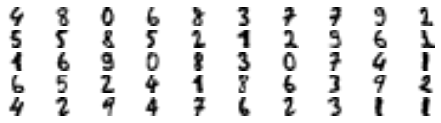

In [191]:
plt.figure(figsize=(8, 2))
for index, X_representative_digit in enumerate(X_representative_digits):
    plt.subplot(k // 10, 10, index + 1)
    plt.imshow(X_representative_digit.reshape(8, 8), cmap="binary", interpolation="bilinear")
    plt.axis('off')

plt.show()

In [192]:
y_representative_digits = np.array([
    4, 8, 0, 6, 8, 3, 7, 7, 9, 2,
    5, 5, 8, 5, 2, 1, 2, 9, 6, 1,
    1, 6, 9, 0, 8, 3, 0, 7, 4, 1,
    6, 5, 2, 4, 1, 8, 6, 3, 9, 2,
    4, 2, 9, 4, 7, 6, 2, 3, 1, 1])

In [193]:
print(X_representative_digits.shape)
print(y_representative_digits.shape)

(50, 64)
(50,)


Now we have a dataset with just 50 labeled instance, but instead of being completely random instances, each of them is a **representative image of its cluster**. 

Let's see if the performance is any better:

In [194]:
log_reg = LogisticRegression(multi_class="ovr", solver="lbfgs", max_iter=5000, random_state=42)
log_reg.fit(X_representative_digits, y_representative_digits)
log_reg.score(X_test, y_test)

0.9222222222222223

Wow! We jumped from 83.3% accuracy to 92.2%!

We are still training on only 50 instances, however we have **used clustering to select a better subset.**

Since it's often costly and painful to label instances, especially when it has to be done manually by experts, it's a good idea to make them label representative instances rather than just random instances.

But perhaps we can go one step further:
- what if we propagated the labels to all the other instances in the same cluster?
- All instances in the same cluster get the same labels as their respective representative observation
- This is typically called **label propagation**

In [195]:
y_train_propagated = np.empty(len(X_train), dtype=np.int32)
y_train_propagated.shape

(1347,)

In [196]:
np.unique(kmeans.labels_)

array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16,
       17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33,
       34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49],
      dtype=int32)

In [197]:
for i in range(k):
    y_train_propagated[kmeans.labels_==i] = y_representative_digits[i]
    
y_train_propagated.shape

(1347,)

In [198]:
log_reg = LogisticRegression(multi_class="ovr", solver="lbfgs", max_iter=5000, random_state=42)
log_reg.fit(X_train, y_train_propagated)

LogisticRegression(max_iter=5000, multi_class='ovr', random_state=42)

In [199]:
log_reg.score(X_test, y_test)

0.9333333333333333

We got a tiny little accuracy boost. Better than nothing, but we should probably have propagated the labels only to the instances closest to the centroid, because by propagating to the full cluster, we have certainly included some outliers. 

Let's only propagate the labels to the 20th percentile closest to the centroid:

In [204]:
percentile_closest = 20

X_cluster_dist = X_digits_dist[np.arange(len(X_train)), kmeans.labels_]
for i in range(k):
    in_cluster = (kmeans.labels_ == i)
    cluster_dist = X_cluster_dist[in_cluster]
    cutoff_distance = np.percentile(cluster_dist, percentile_closest)
    above_cutoff = (X_cluster_dist > cutoff_distance)
    X_cluster_dist[in_cluster & above_cutoff] = -1
    
X_cluster_dist.shape

(1347,)

In [205]:
partially_propagated = (X_cluster_dist != -1)
X_train_partially_propagated = X_train[partially_propagated]
y_train_partially_propagated = y_train_propagated[partially_propagated]

y_train_partially_propagated.shape

(291,)

In [206]:
log_reg = LogisticRegression(multi_class="ovr", solver="lbfgs", max_iter=5000, random_state=42)
log_reg.fit(X_train_partially_propagated, y_train_partially_propagated)

LogisticRegression(max_iter=5000, multi_class='ovr', random_state=42)

In [207]:
log_reg.score(X_test, y_test)

0.94

Nice! With just 50 labeled instances (just 5 examples per class on average!), we got 94% performance, which is pretty close to the performance of logistic regression on the fully labeled _digits_ dataset (which was 96.9%).

This is because the propagated labels are actually pretty good: their accuracy is very close to 99%:

In [208]:
np.mean(y_train_partially_propagated == y_train[partially_propagated])

0.9896907216494846

You could now do a few iterations of *active learning*:
1. Manually label the instances that the classifier is least sure about, if possible by picking them in distinct clusters.
2. Train a new model with these additional labels.

## DBSCAN

This algorithm defines clusters as continuous regions of high density. Here is how it works: 
- For each instance, the algorithm counts how many instances are located within a small distance $ε$ (epsilon) from it. This region is called the instance’s **ε-neighborhood**.
- If an instance has at least `min_samples` instances in its **ε-neighborhood** (including itself), then it is considered a core instance. 
- **Core instances are those that are located in dense regions.** 
- All instances in the neighborhood of a core instance belong to the same cluster. 
    - This neighborhood may include other core instances; **a long sequence of neighboring core instances forms a single cluster.**
- Any instance that is not a core instance and does not have one in its neighborhood is considered an **anomaly**.

<img src="module8_images/02_dbscan.gif" width="500"/>


This algorithm works well if all the clusters are dense enough and if they are well separated by low-density regions. 

The DBSCAN class in Scikit-Learn is as simple to use as you might expect:

In [209]:
from sklearn.datasets import make_moons

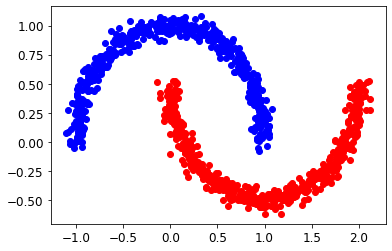

In [210]:
X, y = make_moons(n_samples=1000, noise=0.05, random_state=42)
plt.scatter(X[y==0,0],X[y==0,1], c='b')
plt.scatter(X[y==1,0],X[y==1,1], c='r')

In [211]:
from sklearn.cluster import DBSCAN

In [212]:
dbscan = DBSCAN(eps=0.05, min_samples=5)
dbscan.fit(X)

DBSCAN(eps=0.05)

In [213]:
dbscan.labels_[:10]

array([ 0,  2, -1, -1,  1,  0,  0,  0,  2,  5])

Notice that some instances have a cluster index equal to –1:
- This means that they are **considered as anomalies by the algorithm**. 

The indices of the **core instances** are available in the `core_sample_indices_` instance variable, and the core instances themselves are available in the `components_` instance variable: 


In [214]:
len(dbscan.core_sample_indices_)

808

In [215]:
dbscan.core_sample_indices_[:10]

array([ 0,  4,  5,  6,  7,  8, 10, 11, 12, 13])

In [216]:
idx = dbscan.core_sample_indices_
X[idx][0:5]

array([[-0.02137124,  0.40618608],
       [-0.84192557,  0.53058695],
       [ 0.58930337, -0.32137599],
       [ 0.29248724, -0.20696309],
       [-0.02637836,  0.44766267]])

In [217]:
dbscan.components_[0:5]

array([[-0.02137124,  0.40618608],
       [-0.84192557,  0.53058695],
       [ 0.58930337, -0.32137599],
       [ 0.29248724, -0.20696309],
       [-0.02637836,  0.44766267]])

In [218]:
# Get colors list
import matplotlib
colors = list(matplotlib.colors.cnames.keys())
colors.remove('red')
np.random.choice(colors,5)

array(['lightsteelblue', 'dimgray', 'lightsteelblue', 'lightcoral',
       'lightpink'], dtype='<U20')

N COMPONENTS: 888
N ANOMALIES: 36


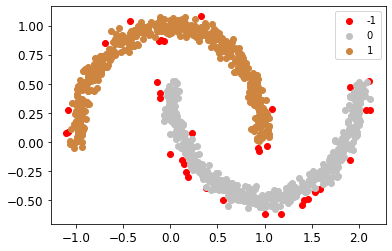

In [222]:
model = DBSCAN(eps=0.06, min_samples=5)
model.fit(X)
labels = np.unique(model.labels_)
print("N COMPONENTS:", model.components_.shape[0])
print("N ANOMALIES:", sum(model.labels_==-1))
cs = np.random.choice(colors,len(labels))
for i,c in zip(labels, cs):
    if i==-1:
        plt.scatter(X[model.labels_==i,0], X[model.labels_==i,1], c='r', label=i)
    else:
        plt.scatter(X[model.labels_==i,0], X[model.labels_==i,1], c=c, label=i)
plt.legend()

N COMPONENTS: 935
N ANOMALIES: 15


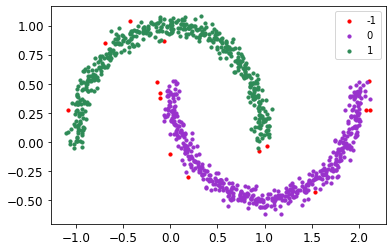

In [221]:
model = DBSCAN(eps=0.07, min_samples=5)
model.fit(X)
labels = np.unique(model.labels_)
print("N COMPONENTS:", model.components_.shape[0])
print("N ANOMALIES:", sum(model.labels_==-1))
cs = np.random.choice(colors,len(labels))
for i,c in zip(labels, cs):
    if i==-1:
        plt.scatter(X[model.labels_==i,0], X[model.labels_==i,1], c='r', label=i,s=10)
    else:
        plt.scatter(X[model.labels_==i,0], X[model.labels_==i,1], c=c, label=i,s=10)
plt.legend()

In [223]:
dbscan2 = DBSCAN(eps=0.2)
dbscan2.fit(X)

DBSCAN(eps=0.2)

In [224]:
def plot_dbscan(dbscan, X, size, show_xlabels=True, show_ylabels=True):
    core_mask = np.zeros_like(dbscan.labels_, dtype=bool)
    core_mask[dbscan.core_sample_indices_] = True
    anomalies_mask = dbscan.labels_ == -1
    non_core_mask = ~(core_mask | anomalies_mask)

    cores = dbscan.components_
    anomalies = X[anomalies_mask]
    non_cores = X[non_core_mask]
    
    plt.scatter(cores[:, 0], cores[:, 1],
                c=dbscan.labels_[core_mask], marker='o', s=size, cmap="Paired")
    plt.scatter(cores[:, 0], cores[:, 1], marker='*', s=20, c=dbscan.labels_[core_mask])
    plt.scatter(anomalies[:, 0], anomalies[:, 1],
                c="r", marker="x", s=100)
    plt.scatter(non_cores[:, 0], non_cores[:, 1], c=dbscan.labels_[non_core_mask], marker=".")
    if show_xlabels:
        plt.xlabel("$x_1$", fontsize=14)
    else:
        plt.tick_params(labelbottom=False)
    if show_ylabels:
        plt.ylabel("$x_2$", fontsize=14, rotation=0)
    else:
        plt.tick_params(labelleft=False)
    plt.title("eps={:.2f}, min_samples={}".format(dbscan.eps, dbscan.min_samples), fontsize=14)

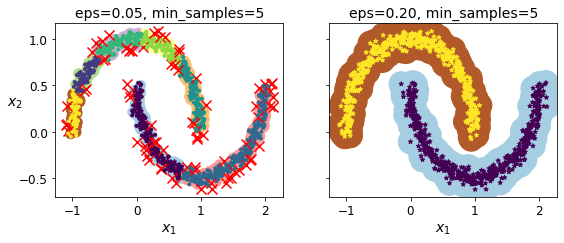

In [225]:
plt.figure(figsize=(9, 3.2))

plt.subplot(121)
plot_dbscan(dbscan, X, size=100)

plt.subplot(122)
plot_dbscan(dbscan2, X, size=600, show_ylabels=False)

plt.show()


Somewhat surprisingly, the DBSCAN class **does not have a `predict()` method, it has a `fit_predict()` method.** 

- In other words, it cannot predict which cluster a new instance belongs to. 

- This implementation decision was made because different classification algorithms can be better for different tasks, so the authors decided to let the user choose which one to use.

To implement a predcit method, we need to use a `KNN`:

In [226]:
dbscan = dbscan2

In [227]:
from sklearn.neighbors import KNeighborsClassifier

In [228]:
knn = KNeighborsClassifier(n_neighbors=50)
knn.fit(dbscan.components_, dbscan.labels_[dbscan.core_sample_indices_])

KNeighborsClassifier(n_neighbors=50)

In [229]:
X_new = np.array([[-0.5, 0], [0, 0.5], [1, -0.1], [2, 1]])
knn.predict(X_new)

array([1, 0, 1, 0])

In [230]:
knn.predict_proba(X_new)

array([[0.18, 0.82],
       [1.  , 0.  ],
       [0.12, 0.88],
       [1.  , 0.  ]])

Note that we only trained the classifier on the core instances, but we could also have chosen to train it on all the instances, or all but the anomalies. **This choice depends on the final task.**
- The decision boundary is represented in the image below (the crosses represent the four instances in `X_new`). 

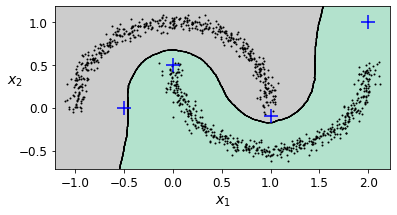

In [231]:
plt.figure(figsize=(6, 3))
plot_decision_boundaries(knn, X, show_centroids=False)
plt.scatter(X_new[:, 0], X_new[:, 1], c="b", marker="+", s=200, zorder=10)
plt.show()

Notice that since there is no anomaly in the training set, the classifier always chooses a cluster, even when that cluster is far away. 
- It is fairly straightforward to introduce a **maximum distance**, in which case the two instances that are far away from both clusters are classified as anomalies. 
- To do this, use the `kneighbors()` method of the KNeighborsClassifier: 
- Given a set of instances, it returns the distances and the indices of the k nearest neighbors in the training set (two matrices, each with k columns)

In [232]:
y_dist, y_pred_idx = knn.kneighbors(X_new, n_neighbors=1)
y_pred = dbscan.labels_[dbscan.core_sample_indices_][y_pred_idx]
y_pred[y_dist > 0.2] = -1
y_pred.ravel()

array([-1,  0,  1, -1])

# Other Clustering Algorithms

- https://towardsdatascience.com/the-5-clustering-algorithms-data-scientists-need-to-know-a36d136ef68
- https://scikit-learn.org/stable/modules/clustering.html



## Agglomerative clustering
Hierarchical clustering algorithms fall into 2 categories: **top-down or bottom-up.**
- Bottom-up algorithms treat each data point as a single cluster and then **successively merge (or agglomerate) pairs of clusters until all clusters have been merged into a single cluster that contains all data points.** 
- Bottom-up hierarchical clustering is therefore called **hierarchical agglomerative clustering or HAC**. 

This hierarchy of clusters is **represented as a tree** (or dendrogram). 
- The root of the tree is the unique cluster that gathers all the samples, the leaves being the clusters with only one sample. 

Here are the main steps:
1. We begin by treating each data point as a single cluster. 
2. We then select a distance metric that measures the distance between two clusters. 
    - We will use the average distance between data points in the first cluster and data points in the second cluster (**average linkage**). 
    - Note that the algorithm is not overly sensitive to the choice of distance metric; all of them tend to work equally well.
3. On each iteration, we combine two clusters into one. The two clusters to be combined are selected as those with the **smallest average linkage**. 
4. Step 3 is repeated until we reach the root of the tree (we only have one cluster which contains all data points). 
    - In this way we can select how many clusters we want in the end, simply by choosing when to stop combining the clusters i.e when we stop building the tree!
- Hierarchical clustering does not require us to specify the number of clusters and we can even select which number of clusters looks best since we are building a tree. 

<img src="module8_images/03_agglom.gif" size=500/>


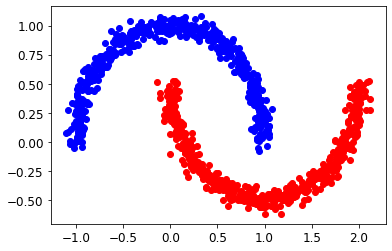

In [233]:
from sklearn.datasets import make_moons
X, y = make_moons(n_samples=1000, noise=0.05, random_state=42)
plt.scatter(X[y==0,0],X[y==0,1], c='b')
plt.scatter(X[y==1,0],X[y==1,1], c='r')


In [234]:
from sklearn.cluster import AgglomerativeClustering
agg = AgglomerativeClustering(linkage="complete", n_clusters=2).fit(X)

In [235]:
def learned_parameters(estimator):
    return [attrib for attrib in dir(estimator) if attrib.endswith("_") and not attrib.startswith("_")]

In [236]:
learned_parameters(agg)

['children_',
 'labels_',
 'n_clusters_',
 'n_connected_components_',
 'n_features_in_',
 'n_leaves_']

In [237]:
agg.n_leaves_

1000

In [238]:
# The children of each non-leaf node. Values less than `n_samples` correspond to leaves of the tree which are the original samples.
# A node `i` greater than or equal to `n_samples` is a non-leaf node and has children `children_[i - n_samples]`. 
sorted(list(agg.children_.tolist()))[0:10]

[[0, 1102],
 [1, 1556],
 [2, 1385],
 [3, 701],
 [4, 774],
 [5, 1568],
 [6, 1075],
 [7, 958],
 [8, 647],
 [9, 321]]

In [239]:
agg.children_.max()

1997

0.829


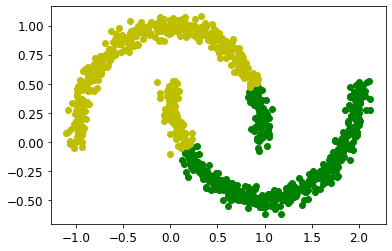

In [240]:
print(sum(~agg.labels_.astype(bool)==y)/len(y))
plt.scatter(X[agg.labels_==0,0],X[agg.labels_==0,1], c='g')
plt.scatter(X[agg.labels_==1,0],X[agg.labels_==1,1], c='y')


## Meanshift Clustering


Meanshift clustering is widely used in real-world data analysis (e.g., image segmentation) because it’s **non-parametric and doesn’t require any predefined shape of the clusters in the feature space.** 

The algorithm uses a **sliding-window-based** approach to find dense areas of data points. 
- It is a **centroid-based algorithm** meaning that the goal is to locate the center points of each group/class
- It does this by updating candidates for center points to be the **mean of the points within the sliding-window.** 
- These candidate windows are then filtered in a post-processing stage to eliminate **near-duplicates**, forming the final set of center points and their corresponding groups.

<img src="module8_images/04_meanshift.gif" size=500/>

- Here are the main steps:
    1. We begin with multiple circular sliding windows centered at randomly selected points and having radius r as the kernel. 
        - Mean shift is a hill-climbing algorithm that involves shifting this kernel iteratively to a higher density region on each step until convergence.
    2. At every iteration, the sliding window is shifted towards regions of higher density by shifting the center point to the mean of the points within the window (hence the name). The density within the sliding window is **proportional to the number of points inside it.** 
        - **By shifting to the mean of the points in the window it will gradually move towards areas of higher point density.**
    3. We continue shifting the sliding window according to the mean until there is no direction at which a shift can accommodate more points inside the kernel. 
    4. This process of steps 1 to 3 is done with **many sliding windows until all points lie within a window**. 
        - When multiple sliding windows overlap the window containing the most points is preserved. 
    5. The data points are then clustered according to the sliding window in which they reside.

<img src="module8_images/05_meanshift.gif" size=500/>


- In contrast to K-means clustering, there is **no need to select the number of clusters as mean-shift automatically discovers this.** 
- The fact that the cluster centers converge towards the points of maximum density is also quite desirable as it is quite intuitive to understand and fits well in a naturally data-driven sense. 
- The drawback is that the selection of the window size/radius “r” can be non-trivial.

CLUSTERS: [0]
0.5


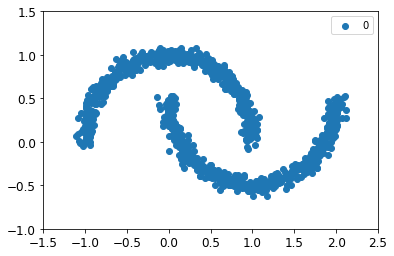

In [241]:
from sklearn.cluster import MeanShift

# Bandwidth too large
ms = MeanShift(bandwidth=0.75, cluster_all=True) 
ms.fit(X)

labels = ms.labels_
clusters = sorted(np.unique(labels))
print("CLUSTERS:", clusters)
print(sum(~labels.astype(bool)==y)/len(y))
plt.xlim(-1.5,2.5)
plt.ylim(-1,1.5)
for c in clusters:
    plt.scatter(X[labels==c,0],X[labels==c,1], label=c)
plt.legend()
plt.show()

CLUSTERS: [0, 1, 2, 3]
0.628


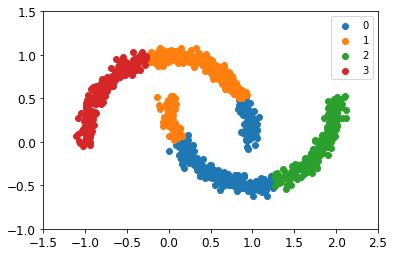

In [242]:
from sklearn.cluster import MeanShift

# Bandwidth too small
ms = MeanShift(bandwidth=0.65, cluster_all=True) 
ms.fit(X)

labels = ms.labels_
clusters = sorted(np.unique(labels))
print("CLUSTERS:", clusters)
print(sum(~labels.astype(bool)==y)/len(y))
plt.xlim(-1.5,2.5)
plt.ylim(-1,1.5)
for c in clusters:
    plt.scatter(X[labels==c,0],X[labels==c,1], label=c)
plt.legend()
plt.show()

CLUSTERS: [0, 1]
0.859


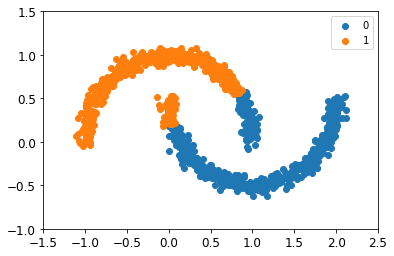

In [246]:
from sklearn.cluster import MeanShift

# Bandwidth just right
ms = MeanShift(bandwidth=0.70, cluster_all=True) 
ms.fit(X)

labels = ms.labels_
clusters = sorted(np.unique(labels))
print("CLUSTERS:", clusters)
print(sum(~labels.astype(bool)==y)/len(y))
plt.xlim(-1.5,2.5)
plt.ylim(-1,1.5)
for c in clusters:
    plt.scatter(X[labels==c,0],X[labels==c,1], label=c)
plt.legend()
plt.show()

## Spectral Clustering

In [247]:
from sklearn.cluster import SpectralClustering

In [248]:
sc1 = SpectralClustering(n_clusters=2, gamma=100, random_state=42)
sc1.fit(X)

SpectralClustering(gamma=100, n_clusters=2, random_state=42)

In [249]:
sc2 = SpectralClustering(n_clusters=2, gamma=1, random_state=42)
sc2.fit(X)

SpectralClustering(gamma=1, n_clusters=2, random_state=42)

In [250]:
np.percentile(sc1.affinity_matrix_, 95)

0.04251990648936265

In [251]:
def plot_spectral_clustering(sc, X, size, alpha, show_xlabels=True, show_ylabels=True):
    plt.scatter(X[:, 0], X[:, 1], marker='o', s=size, c='gray', cmap="Paired", alpha=alpha)
    plt.scatter(X[:, 0], X[:, 1], marker='o', s=30, c='w')
    plt.scatter(X[:, 0], X[:, 1], marker='.', s=10, c=sc.labels_, cmap="Paired")
    
    if show_xlabels:
        plt.xlabel("$x_1$", fontsize=14)
    else:
        plt.tick_params(labelbottom=False)
    if show_ylabels:
        plt.ylabel("$x_2$", fontsize=14, rotation=0)
    else:
        plt.tick_params(labelleft=False)
    plt.title("RBF gamma={}".format(sc.gamma), fontsize=14)

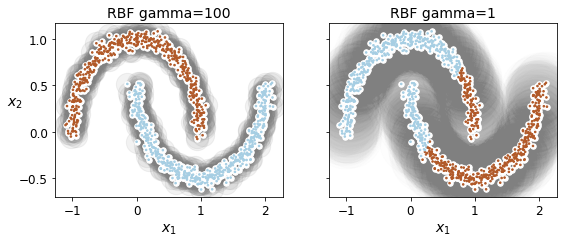

In [252]:
plt.figure(figsize=(9, 3.2))

plt.subplot(121)
plot_spectral_clustering(sc1, X, size=500, alpha=0.1)

plt.subplot(122)
plot_spectral_clustering(sc2, X, size=4000, alpha=0.01, show_ylabels=False)

plt.show()


# Gaussian Mixtures


Before we jump into Gaussian mixture models, lets take a look at some of the **weaknesses of k-means and think about how we might improve the cluster model.** 

As we saw in the previous section, given simple, well-separated data, k-means finds suitable clustering results.
- One way to think about the k-means model is that it **places a circle (or, in higher dimensions, a hyper-sphere) at the center of each cluster, with a radius defined by the most distant point in the cluster.**
- This radius acts as a **hard cutoff for cluster assignment within the training set:**
    - any point outside this circle is not considered a member of the cluster.



In [253]:
from sklearn.cluster import KMeans
from scipy.spatial.distance import cdist
from sklearn.datasets import make_blobs

X, y = make_blobs(n_samples=5000, centers=4, cluster_std=0.60, random_state=0)

X_resampled = []
y_resampled = []
for i in sorted(np.unique(y)):
    n = np.random.randint(50,700)
    samp = X[y==i]
    idxs = np.random.randint(0, samp.shape[0], n)
    samp = samp[idxs]
    X_resampled.append(samp)
    y_resampled.append(np.repeat(i, samp.shape[0]))
    print(samp.shape)
X = np.vstack(X_resampled)
y = np.hstack(y_resampled)

(253, 2)
(244, 2)
(647, 2)
(413, 2)


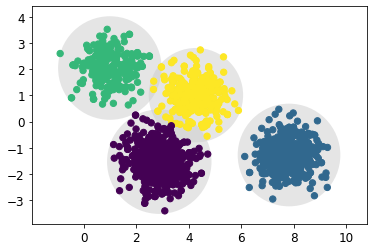

In [254]:

X = X[:, ::-1] # flip axes for better plotting

def plot_kmeans(kmeans, X, n_clusters=4, rseed=0, ax=None):
    labels = kmeans.fit_predict(X)

    # plot the input data
    ax = ax or plt.gca()
    ax.axis('equal')
    ax.scatter(X[:, 0], X[:, 1], c=labels, s=40, cmap='viridis', zorder=2)

    # plot the representation of the KMeans model
    centers = kmeans.cluster_centers_
    radii = [cdist(X[labels == i], [center]).max()
             for i, center in enumerate(centers)]
    for c, r in zip(centers, radii):
        ax.add_patch(plt.Circle(c, r, fc='#CCCCCC', lw=3, alpha=0.5, zorder=1))
        
kmeans = KMeans(n_clusters=4, random_state=0)
plot_kmeans(kmeans, X)

An important observation for k-means is that these **cluster models must be circular:** 
- k-means has no built-in way of accounting for **oblong or elliptical clusters**. 

So, for example, if we take the same data and transform it, the cluster assignments end up becoming muddled:



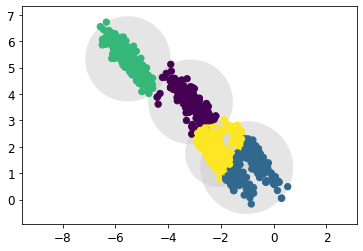

In [255]:
rng = np.random.RandomState(13)
X_stretched = np.dot(X, rng.randn(2, 2))

kmeans = KMeans(n_clusters=4, random_state=0)
plot_kmeans(kmeans, X_stretched)

By eye, we recognize that these transformed clusters are non-circular, and thus circular clusters would be a poor fit. Nevertheless, **k-means is not flexible enough to account for this, and tries to force-fit the data into four circular clusters.** This results in a mixing of cluster assignments where the resulting circles overlap. 
- One might imagine addressing this particular situation by preprocessing the data with PCA, but in practice there is no guarantee that such a global operation will circularize the individual data.

These two disadvantages of k-means — **its lack of flexibility in cluster shape and lack of probabilistic cluster assignment** — mean that for many datasets (especially low-dimensional datasets) it may not perform as well as you might hope.

You might imagine addressing these weaknesses by generalizing the k-means model: 
- For example, you could measure uncertainty in cluster assignment by comparing the distances of each point to all cluster centers, rather than focusing on just the closest. 
- You might also imagine allowing the cluster boundaries to be ellipses rather than circles, so as to account for non-circular clusters. 

It turns out **these are two essential components of a different type of clustering model, Gaussian mixture models.**

## GMM Overview
A Gaussian mixture model (GMM) attempts to find a **mixture of multi-dimensional Gaussian probability distributions** that best model any input dataset (here are a couple good links on multivatiate gaussians for review: https://www.youtube.com/watch?v=h4jvu8PW8YE or https://brilliant.org/wiki/gaussian-mixture-model/):
- It assumes that each instance is generated from one of K Gaussian distributions
- Each distribution can have a different ellipsoidal `shape`, `size`, `density`, and `orientation`.

There are several GMM variants. In the simplest variant, implemented in the `GaussianMixture` class, you must know in advance the number `k` of Gaussian distributions. The dataset `X` is assumed to have been generated through the following probabilistic process: 

- For each instance, a cluster is picked randomly from among k clusters. The probability of choosing the $j^{th}$ cluster is defined by the cluster’s weight, $ϕ( j )$. 

- The index of the cluster chosen for the $i^{th}$ instance is noted $z ( i )$.

- If $z ( i ) = j$ , meaning the $i^{th}$ instance has been assigned to the $j^{th}$ cluster, the location $x ( i )$ of this instance is sampled randomly from the Gaussian distribution with mean $μ ( j )$ and covariance matrix $Σ ( j )$ . This is noted:

$
X^i \sim \mathcal{N}(\mu^j,Σ^j)
$

This generative process can be represented as a graphical model:


<img src="module8_images/06_gausian.png" width="500"/>


Here is how to interpret the plot above:
- The circles represent random variables.
- The squares represent fixed values (i.e., parameters of the model).
- The large rectangles are called `plates` . They indicate that their content is repeated several times.
- The number at the bottom right of each plate indicates how many times its content is repeated. 
    - There are $m$ random variables $z ( i )$ and $m$ random variables $x ( i )$ . 
    - There are also $k$ means $μ ( j )$ and $k$ covariance matrices $Σ ( j )$ . 
    - There is just one weight vector $ϕ$ (containing all the weights $ϕ (1)$ to $ϕ ( k ) )$
- Each variable $z ( i )$ is drawn from the categorical distribution with weights $ϕ$ . 
- Each variable $x ( i )$ is drawn from the normal distribution, with the mean and covariance defined by its cluster $z(i)$
- The solid arrows represent **conditional dependencies**. For example, the probability distribution for each random variable $z ( i )$ depends on the weight vector $ϕ$ . 
- The squiggly arrow from $z ( i )$ to $x ( i )$ represents a switch: **depending on the value of $z ( i )$ , the instance $x ( i )$ will be sampled from a different Gaussian distribution.** 

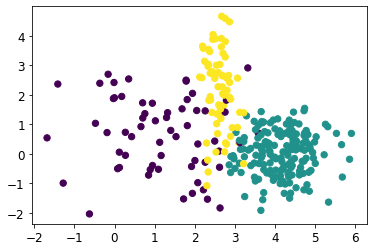

In [ ]:
from scipy import stats

# K latent mv gaussian distributions
dists = [
    stats.multivariate_normal(np.random.normal(size=2),   np.diag(np.random.normal(size=2))**2),
    stats.multivariate_normal(np.random.normal(size=2)+1, np.diag(np.random.normal(size=2))**2),
    stats.multivariate_normal(np.random.normal(size=2)+2, np.diag(np.random.normal(size=2))**2)
]

# phi
phi=[0.2,0.6,0.2]

# Generate data
samples = []
Z = []
for i in range(300):
    # Sample from catergorical dist
    z_i = np.random.choice([0,1,2], p=phi)
    Z.append(z_i)
    # Sample using multivar gaussian z_i
    x_i = dists[z_i].rvs(1)
    samples.append(x_i)
samples = np.stack(samples)
Z = np.stack(Z)
plt.scatter(samples[:,0], samples[:,1], c=Z, s=40, cmap='viridis',)

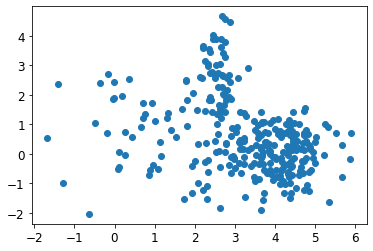

In [ ]:
plt.scatter(samples[:,0], samples[:,1])

As with all sklearn classes, GMMs are easy to train out of the box:

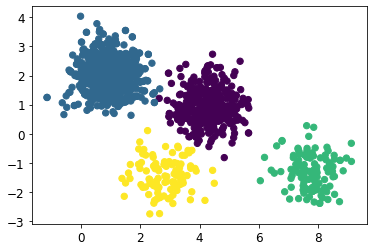

In [ ]:
from sklearn.mixture import GaussianMixture
gm = GaussianMixture(n_components=4).fit(X)
labels = gm.predict(X)
plt.scatter(X[:, 0], X[:, 1], c=labels, s=40, cmap='viridis');

In [ ]:
gm.means_

array([[ 4.29733948,  0.95194757],
       [ 0.92868592,  2.03919971],
       [ 7.76429411, -1.31224306],
       [ 2.83644358, -1.44907405]])

Because GMM is probabilistic model, it is also possible to find probabilistic cluster assignments - in Scikit-Learn this is done using the predict_proba method. 
- This returns a matrix of size [n_samples, n_clusters] which measures the probability that any point belongs to the given cluster:



In [ ]:
probs = gm.predict_proba(X)
print(probs[:5].round(3))

[[0.999 0.    0.    0.001]
 [1.    0.    0.    0.   ]
 [1.    0.    0.    0.   ]
 [1.    0.    0.    0.   ]
 [0.934 0.066 0.    0.   ]]


In [ ]:
yhat = gm.predict(X)
yhat[0:5]

array([0, 0, 0, 0, 0])

We can visualize this uncertainty by, for example, making the size of each point proportional to the certainty of its prediction:


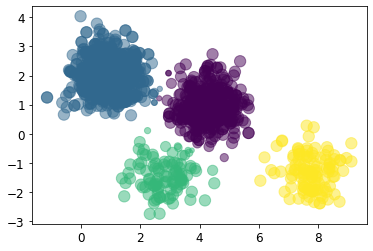

In [ ]:
size = (1+probs.max(1)) ** 7  # ^ to emphasizes differences
plt.scatter(X[:, 0], X[:, 1], c=labels, cmap='viridis', s=size, alpha=0.5);

Let's run our GMM model on our stretched dataset. But first lets create some function to plot ellipses:

In [ ]:
from matplotlib.patches import Ellipse

def draw_ellipse(position, covariance, ax=None, **kwargs):
    """Draw an ellipse with a given position and covariance"""
    ax = ax or plt.gca()
    
    # Convert covariance to principal axes
    if covariance.shape == (2, 2):
        U, s, Vt = np.linalg.svd(covariance)
        angle = np.degrees(np.arctan2(U[1, 0], U[0, 0]))
        width, height = 2 * np.sqrt(s)
    else:
        angle = 0
        width, height = 2 * np.sqrt(covariance)
    
    # Draw the Ellipse
    for nsig in range(1, 4):
        ax.add_patch(Ellipse(position, nsig * width, nsig * height, angle, **kwargs))
        
def plot_gmm(gmm, X, label=True, ax=None):
    ax = ax or plt.gca()
    labels = gmm.fit(X).predict(X)
    if label:
        ax.scatter(X[:, 0], X[:, 1], c=labels, s=40, cmap='viridis', zorder=2)
    else:
        ax.scatter(X[:, 0], X[:, 1], s=40, zorder=2)
    ax.axis('equal')
    
    w_factor = 0.2 / gmm.weights_.max()
    for pos, covar, w in zip(gmm.means_, gmm.covariances_, gmm.weights_):
        draw_ellipse(pos, covar, alpha=w * w_factor)

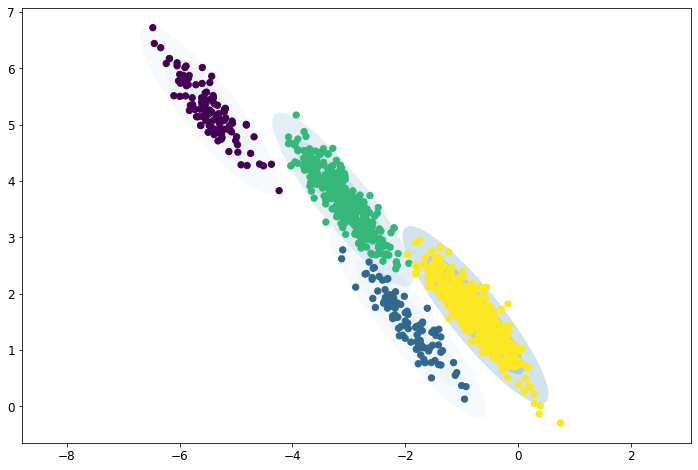

In [ ]:
from sklearn.mixture import GaussianMixture
gm = GaussianMixture(n_components=4, n_init=10, random_state=42)
gm.fit(X_stretched)
plt.figure(figsize=(12,8))
plot_gmm(gm, X_stretched)

In [ ]:
gm.weights_

array([0.09329699, 0.08010502, 0.31459076, 0.51200723])

In [ ]:
# Weights
print(sum(y==0)/len(y))
print(sum(y==1)/len(y))
print(sum(y==2)/len(y))
print(sum(y==3)/len(y))

0.3157894736842105
0.5127591706539075
0.07814992025518341
0.09330143540669857


In [ ]:
# Means
for i in range(4):
    print(X_stretched[y==i][:,0].mean(axis=0), X_stretched[y==i][:,1].mean(axis=0))

-3.106581264248589 3.6680993205925834
-0.7549418805265665 1.624098061141605
-1.9369215025212225 1.456037725121544
-5.472768397656013 5.259532894338877


In [ ]:
gm.means_

array([[-5.47279389,  5.25956286],
       [-1.96025787,  1.49041531],
       [-3.10550513,  3.67178997],
       [-0.75298066,  1.62190524]])

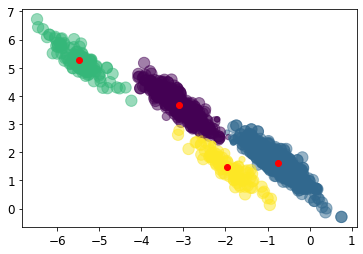

In [ ]:
plt.scatter(X_stretched[:, 0], X_stretched[:, 1], c=labels, cmap='viridis', s=size, alpha=0.5);
plt.scatter(gm.means_[:,0],gm.means_[:,1], c='red')

In [ ]:
#For a refresher on covariance: https://datascienceplus.com/understanding-the-covariance-matrix/
# Covariance
def cov(x, y):
    xbar, ybar = x.mean(), y.mean()
    return np.sum((x - xbar)*(y - ybar))/(len(x) - 1)

# Covariance matrix
def cov_mat(X):
    return np.array([[cov(X[:,0], X[:,0]), cov(X[:,0], X[:,1])], [cov(X[:,1], X[:,0]), cov(X[:,1], X[:,1])]])

# Calculate covariance matrix 
cov_mat(X_stretched.T) # (or with np.cov(X.T))

for i in range(4):
    print(cov_mat(X_stretched[y==i]))

[[ 0.17108951 -0.19063218]
 [-0.19063218  0.26782918]]
[[ 0.18949355 -0.20610113]
 [-0.20610113  0.28006912]]
[[ 0.20646731 -0.21914372]
 [-0.21914372  0.28377596]]
[[ 0.17052757 -0.18052502]
 [-0.18052502  0.24912695]]


In [ ]:
gm.covariances_

array([[[ 0.16908374, -0.17897879],
        [-0.17897879,  0.24698735]],

       [[ 0.21774261, -0.24056884],
        [-0.24056884,  0.31871338]],

       [[ 0.17450973, -0.19212428],
        [-0.19212428,  0.26560758]],

       [[ 0.18678747, -0.20305368],
        [-0.20305368,  0.27672177]]])

## Generating new data
This is a generative model, so you can sample new instances from it (and get their labels):

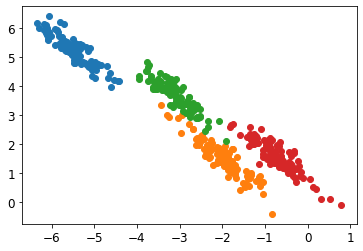

In [ ]:
from scipy import stats
from sklearn.mixture import GaussianMixture
gm = GaussianMixture(n_components=4, n_init=10, random_state=42)
gm.fit(X_stretched)

# Manual data generation
for i in range(gm.means_.shape[0]):
    mu = gm.means_[i]
    cov =  gm.covariances_[i]
    # Sample
    sample = stats.multivariate_normal(mu, cov).rvs(100)
    plt.scatter(sample[:,0],sample[:,1])
plt.show()

In [ ]:
# Data generation using `gm.sample`
X_new, y_new = gm.sample(6)
X_new

array([[-1.42070883,  0.90163751],
       [-1.96890003,  1.74110062],
       [-2.9346641 ,  3.32838875],
       [-2.98552211,  3.296002  ],
       [ 0.44583273,  0.3626795 ],
       [-1.27516085,  1.8969833 ]])

In [ ]:
y_new

array([1, 1, 2, 2, 3, 3])

Notice that they are sampled sequentially from each cluster.

It is also possible to estimate the **density of the model at any given location.** 

This is achieved using the `score_samples()` method: 
- for each instance it is given, this method estimates the **log of the probability density function (PDF)** at that location. 
- The greater the score, the higher the density: 

In [ ]:
np.exp(gm.score_samples(X_stretched)[0:5])

array([0.18465073, 0.30031416, 0.35912348, 0.36036836, 0.02186807])

In [ ]:
np.mean(gm.score_samples(X_stretched))

-1.6592731465385249

In [ ]:
gm.score(X_stretched)

-1.6592731465385249

If you compute the exponential of these scores, you get the value of the **PDF at the location of the given instances**. 

These are not probabilities, but probability densities : 
- they can take on any positive value, not just a value between 0 and 1.
- To estimate the probability that an instance will fall within a particular region, **you would have to integrate (area under the curve) the PDF over that region** (if you do so over the entire space of possible instance locations, the result will be 1). 


Let's check that the PDF integrates to 1 over the whole space:
- We just take a large square around the clusters, and chop it into a grid of tiny squares
- then we compute the approximate probability that the instances will be generated in each tiny square (by multiplying the PDF at one corner of the tiny square by the area of the square), and finally summing all these probabilities). 
- The result is very close to 1

In [ ]:
resolution = 100
grid = np.arange(-10, 10, 1 / resolution)
xx, yy = np.meshgrid(grid, grid)
X_full = np.vstack([xx.ravel(), yy.ravel()]).T

pdf = np.exp(gm.score_samples(X_full))
pdf_probas = pdf * (1 / resolution) ** 2
pdf_probas.sum()

1.0000000000000424

Now let's plot the resulting decision boundaries (dashed lines) and density contours:

In [ ]:
from matplotlib.colors import LogNorm

def plot_data(X):
    plt.plot(X[:, 0], X[:, 1], 'k.', markersize=2)

def plot_centroids(centroids, weights=None, circle_color='w', cross_color='k'):
    if weights is not None:
        centroids = centroids[weights > weights.max() / 10]
    plt.scatter(centroids[:, 0], centroids[:, 1],
                marker='o', s=30, linewidths=8,
                color=circle_color, zorder=10, alpha=0.9)
    plt.scatter(centroids[:, 0], centroids[:, 1],
                marker='x', s=50, linewidths=50,
                color=cross_color, zorder=11, alpha=1)
    
def plot_gaussian_mixture(clusterer, X, resolution=1000, show_ylabels=True):
    mins = X.min(axis=0) - 0.1
    maxs = X.max(axis=0) + 0.1
    xx, yy = np.meshgrid(np.linspace(mins[0], maxs[0], resolution),
                         np.linspace(mins[1], maxs[1], resolution))
    Z = -clusterer.score_samples(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    plt.contourf(xx, yy, Z,
                 norm=LogNorm(vmin=1.0, vmax=30.0),
                 levels=np.logspace(0, 2, 12))
    plt.contour(xx, yy, Z,
                norm=LogNorm(vmin=1.0, vmax=30.0),
                levels=np.logspace(0, 2, 12),
                linewidths=1, colors='k')

    Z = clusterer.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)
    plt.contour(xx, yy, Z,
                linewidths=2, colors='r', linestyles='dashed')
    
    plt.plot(X[:, 0], X[:, 1], 'k.', markersize=2)
    plot_centroids(clusterer.means_, clusterer.weights_)

    plt.xlabel("$x_1$", fontsize=14)
    if show_ylabels:
        plt.ylabel("$x_2$", fontsize=14, rotation=0)
    else:
        plt.tick_params(labelleft=False)

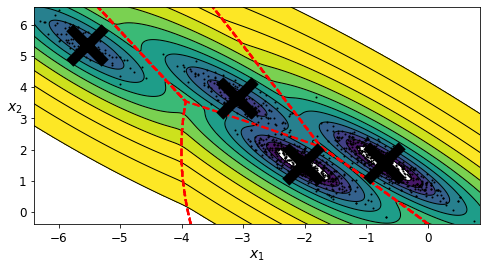

In [ ]:
plt.figure(figsize=(8, 4))

plot_gaussian_mixture(gm, X_stretched)
plt.show()

## Under the hood

This GMM class relies on the **Expectation-Maximization (EM) algorithm**, which has many similarities with the K-Means algorithm: 
1. First it initializes the cluster parameters randomly
2. then it assigns instances to clusters (this is called the expectation step ) 
3. then it updates the cluster parameters (this is called the maximization step)
4. It repeats step 2 and 3 until convergence.

Here's an excellent video on the EM algorithm if you are interesting in digging into the details: https://www.youtube.com/watch?v=xy96ArOpntA

In the context of clustering, you can think of EM as a generalization of K-Means that not only finds the cluster centers ( $μ (1)$ to $μ ( k )$ ), but also their size, shape, and orientation ( $Σ (1)$ to $Σ ( k )$ ), as well as their relative weights ( $ϕ (1)$ to $ϕ ( k )$ ). 

Unlike K-Means, though, **EM uses soft cluster assignments, not hard assignments.** 
- For each instance, during the expectation step, the algorithm estimates the probability that it belongs to each cluster (based on the current cluster parameters). 
- Then, during the maximization step, each cluster is **updated using all the instances in the dataset, with each instance weighted by the estimated probability that it belongs to that cluster.**
- These probabilities are called **the responsibilities of the clusters for the instances**. During the maximization step, each cluster’s update will mostly be impacted by the instances it is most responsible for. 

**NOTE**: Unfortunately, just like K-Means, EM can end up converging to poor solutions, so it needs to be run several times, keeping only the best solution. This is why we set n_init to 10 . **Be careful: by default n_init is set to 1 .** 

In [ ]:
from sklearn.mixture import GaussianMixture
gm = GaussianMixture(n_components=4, n_init=10, random_state=42)
gm.fit(X_stretched)

GaussianMixture(n_components=4, n_init=10, random_state=42)

In [ ]:
# EM iterations will stop when the lower bound average gain is below threshold set by `tol` param
print(gm.converged_)
print(gm.n_iter_)

True
5


When there are many dimensions, or many clusters, or few instances, **EM can struggle to converge to the optimal solution.** You might need to reduce the difficulty of the task by **limiting the number of parameters that the algorithm has to learn.**

One way to do this is to limit the range of shapes and orientations that the clusters can have. This can be achieved by **imposing constraints on the covariance matrices.** To do this, set the `covariance_type` hyperparameter to one of the following values: 

* `"full"` (default): no constraint, all clusters can take on any ellipsoidal shape of any size.
* `"tied"`: all clusters must have the same shape, which can be any ellipsoid (i.e., they all share the same covariance matrix).
* `"spherical"`: all clusters must be spherical, but they can have different diameters (i.e., different variances).
* `"diag"`: clusters can take on any ellipsoidal shape of any size, but the ellipsoid's axes must be parallel to the axes (i.e., the covariance matrices must be diagonal).

In [ ]:
gm_full = GaussianMixture(n_components=4, n_init=10, covariance_type="full", random_state=42)
gm_tied = GaussianMixture(n_components=4, n_init=10, covariance_type="tied", random_state=42)
gm_spherical = GaussianMixture(n_components=4, n_init=10, covariance_type="spherical", random_state=42)
gm_diag = GaussianMixture(n_components=4, n_init=10, covariance_type="diag", random_state=42)
gm_full.fit(X_stretched)
gm_tied.fit(X_stretched)
gm_spherical.fit(X_stretched)
gm_diag.fit(X_stretched)

GaussianMixture(covariance_type='diag', n_components=4, n_init=10,
                random_state=42)

In [ ]:
gm_full.covariances_

array([[[ 0.18452315, -0.20449254],
        [-0.20449254,  0.28535203]],

       [[ 0.18847745, -0.19949379],
        [-0.19949379,  0.27295151]],

       [[ 0.16444736, -0.16787416],
        [-0.16787416,  0.23192601]],

       [[ 0.1393088 , -0.15227366],
        [-0.15227366,  0.23173578]]])

In [ ]:
def compare_gaussian_mixtures(gm1, gm2, X):
    plt.figure(figsize=(9, 4))

    plt.subplot(121)
    plot_gaussian_mixture(gm1, X)
    plt.title('covariance_type="{}"'.format(gm1.covariance_type), fontsize=14)

    plt.subplot(122)
    plot_gaussian_mixture(gm2, X, show_ylabels=False)
    plt.title('covariance_type="{}"'.format(gm2.covariance_type), fontsize=14)


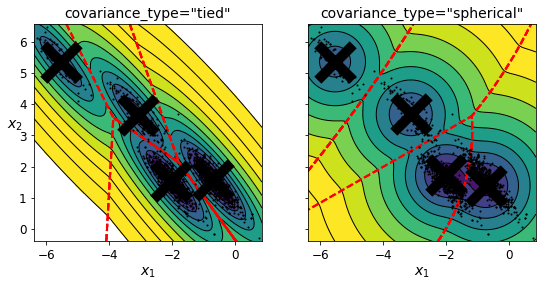

In [ ]:
compare_gaussian_mixtures(gm_tied, gm_spherical, X_stretched)
plt.show()

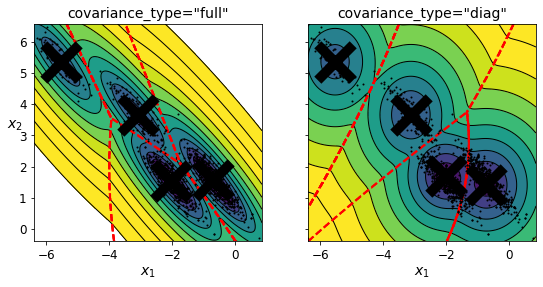

In [ ]:
compare_gaussian_mixtures(gm_full, gm_diag, X_stretched)
# plt.tight_layout()
plt.show()

## Anomaly Detection using Gaussian Mixtures

Gaussian Mixtures can be used for _anomaly detection_: 
- instances located in low-density regions can be considered anomalies. 
- You must define what density threshold you want to use. 

For example, in a manufacturing company that tries to detect defective products, the ratio of defective products is usually well-known. Say it is equal to 4%, then you can set the density threshold to be the value that results in having 4% of the instances located in areas below that threshold density:

In [ ]:
densities = gm.score_samples(X_stretched)
density_threshold = np.percentile(densities, 4)
anomalies = X_stretched[densities < density_threshold]

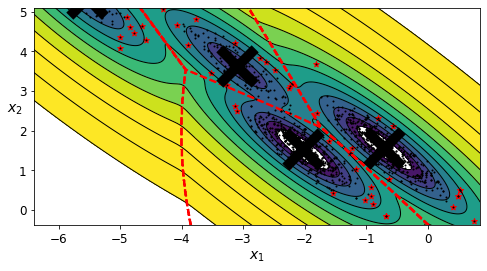

In [ ]:
plt.figure(figsize=(8, 4))

plot_gaussian_mixture(gm, X_stretched)
plt.scatter(anomalies[:, 0], anomalies[:, 1], color='r', marker='*')
plt.ylim(top=5.1)
plt.show()

## Model selection

We cannot use the inertia or the silhouette score because they **both assume that the clusters are spherical**. 

Instead, we can try to find the model that **minimizes a theoretical information criterion** such as the Bayesian Information Criterion (BIC) or the Akaike Information Criterion (AIC):

${BIC} = {\log(m)p - 2\log({\hat L})}$

${AIC} = 2p - 2\log(\hat L)$

* $m$ is the number of instances.
* $p$ is the number of parameters learned by the model.
* $\hat L$ is the maximized value of the likelihood function of the model. 
    - Likelihood refers to how well a sample provides support for particular values of a parameter in a model


Both BIC and AIC penalize models that have more parameters to learn (e.g., more clusters), and reward models that fit the data well (i.e., models that give a high likelihood to the observed data).

In [ ]:
gm.bic(X)

289603.7877970942

In [ ]:
gm.aic(X)

289486.05479336577

**NOTE:** The terms “probability” and “likelihood” are often used interchangeably in the English language, but they have **very different meanings in statistics.** 
- Given a statistical model with some parameters $θ$ , the word “probability” is used to describe how plausible a future outcome $x$ is (knowing the parameter values θ )
    - $p(data | distribution)$
    - If you want to estimate the probability that $x$ will fall between –2 and +2 (or any given range under the distribution), you must calculate the integral of the PDF on this range.



- While the word “likelihood” is used to describe how plausible a particular set of parameter values $θ$ are (for example, mean and standard deviation), after the outcome $x$ is known. 
    - $L(distribution | data)$
    - If you don’t know $θ$, and instead if you have observed a single instance x =2.5, you get the likelihood function $L( θ | x =2.5)=f( x =2.5; θ )$.
    - In essence, we want to choose the parameters of the distribution $\theta$ that maximize the likliehood of observing X (over all instances within X). 
    
    
    
- Again, it is important to understand that the **likelihood function is not a probability distribution**: 
    - if you integrate a probability distribution over all possible values of x , you always get 1
    - if you integrate the likelihood function over all possible values of θ , the result can be any positive value. 

Let's calculate the BIC and AIC scores manually:

In [ ]:
n_clusters = 3
n_dims = 2

# Get number of parameters
n_params_for_weights = n_clusters - 1
n_params_for_means = n_clusters * n_dims
n_params_for_covariance = n_clusters * n_dims * (n_dims + 1) // 2
n_params = n_params_for_weights + n_params_for_means + n_params_for_covariance

print("WEIGHTS:", n_params_for_weights)
print("MEANS:", n_params_for_means)
print("COVARIANCE:", n_params_for_covariance)
print("TOTAL:", n_params)

WEIGHTS: 2
MEANS: 6
COVARIANCE: 9
TOTAL: 17


In [ ]:
# avg_density = np.mean(gm.score_samples(X))
max_log_likelihood = gm.score_samples(X).sum() #avg_density * len(X) # log(L^)
print(max_log_likelihood)

-144720.02739668288


In [ ]:
# Score = 
bic = np.log(len(X)) * n_params - 2 * max_log_likelihood
aic = 2 * n_params - 2 * max_log_likelihood

bic, aic

(289561.07483959984, 289474.05479336577)

There's one weight per cluster, but the sum must be equal to 1, so we have one degree of freedom less, hence the -1. Similarly, the degrees of freedom for an $n \times n$ covariance matrix is not $n^2$, but $1 + 2 + \dots + n = \dfrac{n (n+1)}{2}$.

Let's train Gaussian Mixture models with various values of $k$ and measure their BIC:

In [ ]:
from sklearn.metrics import silhouette_score
gms_per_k = [GaussianMixture(n_components=k, n_init=10, random_state=42).fit(X_stretched) for k in range(1, 11)]

# silhouette_scores = [silhouette_score(X_train_pca, model.labels_) for model in kmeans_per_k]
# best_index = np.argmax(silhouette_scores)
# best_k = k_range[best_index]
# best_score = silhouette_scores[best_index]

In [ ]:
gms_per_k = [GaussianMixture(n_components=k, n_init=10, random_state=42).fit(X_stretched) for k in range(1, 11)]

In [ ]:
from sklearn.metrics import silhouette_score
bics = [model.bic(X_stretched) for model in gms_per_k]
aics = [model.aic(X_stretched) for model in gms_per_k]
silh = [silhouette_score(X_stretched, model.predict(X_stretched)) for model in gms_per_k if model.n_components >1]

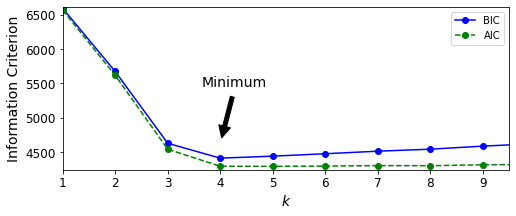

In [ ]:
plt.figure(figsize=(8, 3))
plt.plot(range(1, 11), bics, "bo-", label="BIC")
plt.plot(range(1, 11), aics, "go--", label="AIC")
plt.xlabel("$k$", fontsize=14)
plt.ylabel("Information Criterion", fontsize=14)
plt.axis([1, 9.5, np.min(aics) - 50, np.max(aics) + 50])
plt.annotate('Minimum',
             xy=(4, bics[2]),
             xytext=(0.35, 0.6),
             textcoords='figure fraction',
             fontsize=14,
             arrowprops=dict(facecolor='black', shrink=0.1)
            )
plt.legend()
plt.show()

As you can see, both the BIC and the AIC are lowest when k =3, so it is most likely the best choice. 

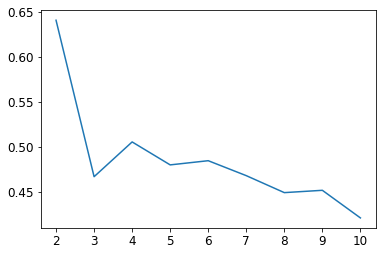

In [ ]:
plt.plot(range(2,11), silh)
plt.show()

Note that we could also search for the best value for the `covariance_type` hyperparameter. 

For example, if it is "spherical" rather than "full" , then the model has significantly fewer parameters to learn, but it does not fit the data as well. 

In [ ]:
min_bic = np.infty

for k in range(1, 11):
    for covariance_type in ("full", "tied", "spherical", "diag"):
        bic = GaussianMixture(n_components=k, n_init=10,
                              covariance_type=covariance_type,
                              random_state=42).fit(X_stretched).bic(X_stretched)
        if bic < min_bic:
            min_bic = bic
            best_k = k
            best_covariance_type = covariance_type

In [ ]:
best_k

4

In [ ]:
best_covariance_type

'tied'

## Variational Bayesian Gaussian Mixtures

Rather than manually searching for the optimal number of clusters, it is possible to use instead the `BayesianGaussianMixture` class which is capable of **giving weights equal (or close) to zero to unnecessary clusters.**

- Just set the number of components to a value that you believe is **greater than the optimal number of clusters**, and the algorithm will eliminate the unnecessary clusters automatically.

In [ ]:
from sklearn.mixture import BayesianGaussianMixture

In [ ]:
bgm = BayesianGaussianMixture(n_components=6, n_init=10, random_state=42)
bgm.fit(X)

BayesianGaussianMixture(n_components=6, n_init=10, random_state=42)

The algorithm automatically detected that only 3 components are needed:

In [ ]:
np.round(bgm.weights_, 2)

array([0.41, 0.4 , 0.13, 0.07, 0.  , 0.  ])

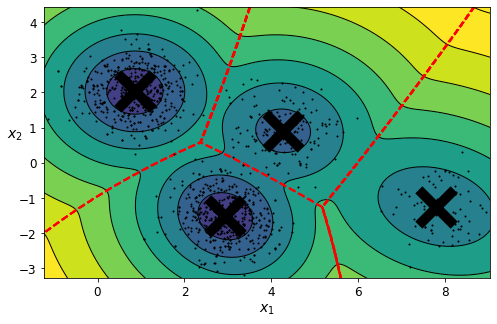

In [ ]:
plt.figure(figsize=(8, 5))
plot_gaussian_mixture(bgm, X)
plt.show()

In [ ]:
bgm_low = BayesianGaussianMixture(n_components=10, max_iter=1000, n_init=1,
                                  weight_concentration_prior=0.01, random_state=42)
bgm_high = BayesianGaussianMixture(n_components=10, max_iter=1000, n_init=1,
                                  weight_concentration_prior=10000, random_state=42)
nn = 73
bgm_low.fit(X[:nn])
bgm_high.fit(X[:nn])

BayesianGaussianMixture(max_iter=1000, n_components=10, random_state=42,
                        weight_concentration_prior=10000)

In [ ]:
np.round(bgm_low.weights_, 2)

array([0.01, 0.54, 0.36, 0.09, 0.  , 0.  , 0.  , 0.  , 0.  , 0.  ])

In [ ]:
np.round(bgm_high.weights_, 2)

array([0.01, 0.01, 0.41, 0.01, 0.24, 0.01, 0.01, 0.01, 0.27, 0.01])

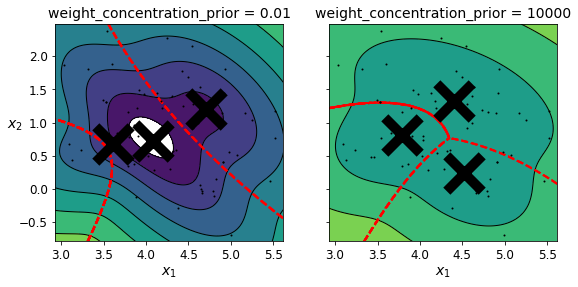

In [ ]:
plt.figure(figsize=(9, 4))

plt.subplot(121)
plot_gaussian_mixture(bgm_low, X[:nn])
plt.title("weight_concentration_prior = 0.01", fontsize=14)

plt.subplot(122)
plot_gaussian_mixture(bgm_high, X[:nn], show_ylabels=False)
plt.title("weight_concentration_prior = 10000", fontsize=14)

plt.show()

Note: the fact that you see only 3 regions in the right plot although there are 4 centroids is not a bug. The weight of the top-right cluster is much larger than the weight of the lower-right cluster, so the probability that any given point in this region belongs to the top right cluster is greater than the probability that it belongs to the lower-right cluster.

In [ ]:
X_moons, y_moons = make_moons(n_samples=1000, noise=0.05, random_state=42)

In [ ]:
bgm = BayesianGaussianMixture(n_components=10, n_init=10, random_state=42)
bgm.fit(X_moons)

BayesianGaussianMixture(n_components=10, n_init=10, random_state=42)

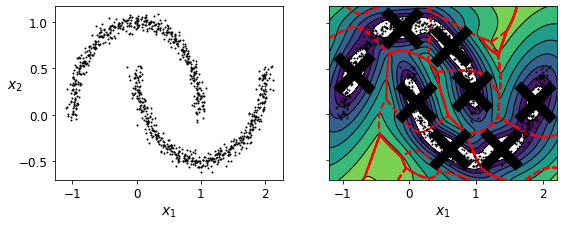

In [ ]:
plt.figure(figsize=(9, 3.2))

plt.subplot(121)
plot_data(X_moons)
plt.xlabel("$x_1$", fontsize=14)
plt.ylabel("$x_2$", fontsize=14, rotation=0)

plt.subplot(122)
plot_gaussian_mixture(bgm, X_moons, show_ylabels=False)

plt.show()

Oops, not great... instead of detecting 2 moon-shaped clusters, the algorithm detected 8 ellipsoidal clusters. However, the density plot does not look too bad, so it might be usable for anomaly detection.

## Likelihood Function

In [ ]:
from scipy.stats import norm

In [ ]:
xx = np.linspace(-6, 4, 101)
ss = np.linspace(1, 2, 101)
XX, SS = np.meshgrid(xx, ss)
ZZ = 2 * norm.pdf(XX - 1.0, 0, SS) + norm.pdf(XX + 4.0, 0, SS)
ZZ = ZZ / ZZ.sum(axis=1)[:,np.newaxis] / (xx[1] - xx[0])

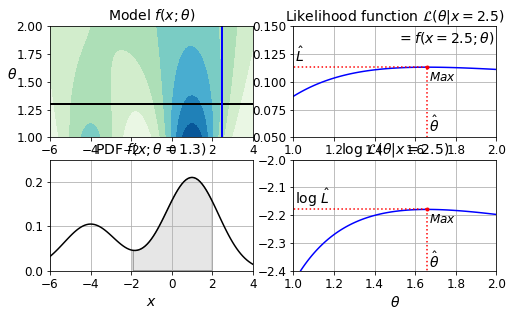

In [ ]:
from matplotlib.patches import Polygon

plt.figure(figsize=(8, 4.5))

x_idx = 85
s_idx = 30

plt.subplot(221)
plt.contourf(XX, SS, ZZ, cmap="GnBu")
plt.plot([-6, 4], [ss[s_idx], ss[s_idx]], "k-", linewidth=2)
plt.plot([xx[x_idx], xx[x_idx]], [1, 2], "b-", linewidth=2)
plt.xlabel(r"$x$")
plt.ylabel(r"$\theta$", fontsize=14, rotation=0)
plt.title(r"Model $f(x; \theta)$", fontsize=14)

plt.subplot(222)
plt.plot(ss, ZZ[:, x_idx], "b-")
max_idx = np.argmax(ZZ[:, x_idx])
max_val = np.max(ZZ[:, x_idx])
plt.plot(ss[max_idx], max_val, "r.")
plt.plot([ss[max_idx], ss[max_idx]], [0, max_val], "r:")
plt.plot([0, ss[max_idx]], [max_val, max_val], "r:")
plt.text(1.01, max_val + 0.005, r"$\hat{L}$", fontsize=14)
plt.text(ss[max_idx]+ 0.01, 0.055, r"$\hat{\theta}$", fontsize=14)
plt.text(ss[max_idx]+ 0.01, max_val - 0.012, r"$Max$", fontsize=12)
plt.axis([1, 2, 0.05, 0.15])
plt.xlabel(r"$\theta$", fontsize=14)
plt.grid(True)
plt.text(1.99, 0.135, r"$=f(x=2.5; \theta)$", fontsize=14, ha="right")
plt.title(r"Likelihood function $\mathcal{L}(\theta|x=2.5)$", fontsize=14)

plt.subplot(223)
plt.plot(xx, ZZ[s_idx], "k-")
plt.axis([-6, 4, 0, 0.25])
plt.xlabel(r"$x$", fontsize=14)
plt.grid(True)
plt.title(r"PDF $f(x; \theta=1.3)$", fontsize=14)
verts = [(xx[41], 0)] + list(zip(xx[41:81], ZZ[s_idx, 41:81])) + [(xx[80], 0)]
poly = Polygon(verts, facecolor='0.9', edgecolor='0.5')
plt.gca().add_patch(poly)

plt.subplot(224)
plt.plot(ss, np.log(ZZ[:, x_idx]), "b-")
max_idx = np.argmax(np.log(ZZ[:, x_idx]))
max_val = np.max(np.log(ZZ[:, x_idx]))
plt.plot(ss[max_idx], max_val, "r.")
plt.plot([ss[max_idx], ss[max_idx]], [-5, max_val], "r:")
plt.plot([0, ss[max_idx]], [max_val, max_val], "r:")
plt.axis([1, 2, -2.4, -2])
plt.xlabel(r"$\theta$", fontsize=14)
plt.text(ss[max_idx]+ 0.01, max_val - 0.05, r"$Max$", fontsize=12)
plt.text(ss[max_idx]+ 0.01, -2.39, r"$\hat{\theta}$", fontsize=14)
plt.text(1.01, max_val + 0.02, r"$\log \, \hat{L}$", fontsize=14)
plt.grid(True)
plt.title(r"$\log \, \mathcal{L}(\theta|x=2.5)$", fontsize=14)

# save_fig("likelihood_function_plot")
plt.show()

# Exercise solutions

## 1. to 9.

See Appendix A.

## 10. Cluster the Olivetti Faces Dataset

*Exercise: The classic Olivetti faces dataset contains 400 grayscale 64 × 64–pixel images of faces. Each image is flattened to a 1D vector of size 4,096. 40 different people were photographed (10 times each), and the usual task is to train a model that can predict which person is represented in each picture. Load the dataset using the `sklearn.datasets.fetch_olivetti_faces()` function.*

In [ ]:
from sklearn.datasets import fetch_olivetti_faces

olivetti = fetch_olivetti_faces()

downloading Olivetti faces from https://ndownloader.figshare.com/files/5976027 to /Users/mciniello/scikit_learn_data


In [ ]:
print(olivetti.DESCR)

.. _olivetti_faces_dataset:

The Olivetti faces dataset
--------------------------

`This dataset contains a set of face images`_ taken between April 1992 and 
April 1994 at AT&T Laboratories Cambridge. The
:func:`sklearn.datasets.fetch_olivetti_faces` function is the data
fetching / caching function that downloads the data
archive from AT&T.

.. _This dataset contains a set of face images: http://www.cl.cam.ac.uk/research/dtg/attarchive/facedatabase.html

As described on the original website:

    There are ten different images of each of 40 distinct subjects. For some
    subjects, the images were taken at different times, varying the lighting,
    facial expressions (open / closed eyes, smiling / not smiling) and facial
    details (glasses / no glasses). All the images were taken against a dark
    homogeneous background with the subjects in an upright, frontal position 
    (with tolerance for some side movement).

**Data Set Characteristics:**

    =================   ===========

In [ ]:
olivetti.target

array([ 0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  1,  1,  1,  1,  1,  1,  1,
        1,  1,  1,  2,  2,  2,  2,  2,  2,  2,  2,  2,  2,  3,  3,  3,  3,
        3,  3,  3,  3,  3,  3,  4,  4,  4,  4,  4,  4,  4,  4,  4,  4,  5,
        5,  5,  5,  5,  5,  5,  5,  5,  5,  6,  6,  6,  6,  6,  6,  6,  6,
        6,  6,  7,  7,  7,  7,  7,  7,  7,  7,  7,  7,  8,  8,  8,  8,  8,
        8,  8,  8,  8,  8,  9,  9,  9,  9,  9,  9,  9,  9,  9,  9, 10, 10,
       10, 10, 10, 10, 10, 10, 10, 10, 11, 11, 11, 11, 11, 11, 11, 11, 11,
       11, 12, 12, 12, 12, 12, 12, 12, 12, 12, 12, 13, 13, 13, 13, 13, 13,
       13, 13, 13, 13, 14, 14, 14, 14, 14, 14, 14, 14, 14, 14, 15, 15, 15,
       15, 15, 15, 15, 15, 15, 15, 16, 16, 16, 16, 16, 16, 16, 16, 16, 16,
       17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 18, 18, 18, 18, 18, 18, 18,
       18, 18, 18, 19, 19, 19, 19, 19, 19, 19, 19, 19, 19, 20, 20, 20, 20,
       20, 20, 20, 20, 20, 20, 21, 21, 21, 21, 21, 21, 21, 21, 21, 21, 22,
       22, 22, 22, 22, 22

*Exercise: Then split it into a training set, a validation set, and a test set (note that the dataset is already scaled between 0 and 1). Since the dataset is quite small, you probably want to use stratified sampling to ensure that there are the same number of images per person in each set.*

In [ ]:
from sklearn.model_selection import StratifiedShuffleSplit

strat_split = StratifiedShuffleSplit(n_splits=1, test_size=40, random_state=42)
train_valid_idx, test_idx = next(strat_split.split(olivetti.data, olivetti.target))
X_train_valid = olivetti.data[train_valid_idx]
y_train_valid = olivetti.target[train_valid_idx]
X_test = olivetti.data[test_idx]
y_test = olivetti.target[test_idx]

strat_split = StratifiedShuffleSplit(n_splits=1, test_size=80, random_state=43)
train_idx, valid_idx = next(strat_split.split(X_train_valid, y_train_valid))
X_train = X_train_valid[train_idx]
y_train = y_train_valid[train_idx]
X_valid = X_train_valid[valid_idx]
y_valid = y_train_valid[valid_idx]

In [ ]:
print(X_train.shape, y_train.shape)
print(X_valid.shape, y_valid.shape)
print(X_test.shape, y_test.shape)

(280, 4096) (280,)
(80, 4096) (80,)
(40, 4096) (40,)


To speed things up, we'll reduce the data's dimensionality using PCA:

In [ ]:
from sklearn.decomposition import PCA

pca = PCA(0.99)
X_train_pca = pca.fit_transform(X_train)
X_valid_pca = pca.transform(X_valid)
X_test_pca = pca.transform(X_test)

pca.n_components_

199

*Exercise: Next, cluster the images using K-Means, and ensure that you have a good number of clusters (using one of the techniques discussed in this chapter).*

In [ ]:
from sklearn.cluster import KMeans

k_range = range(5, 150, 5)
kmeans_per_k = []
for k in k_range:
    print("k={}".format(k))
    kmeans = KMeans(n_clusters=k, random_state=42).fit(X_train_pca)
    kmeans_per_k.append(kmeans)

k=5
k=10
k=15
k=20
k=25
k=30
k=35
k=40
k=45
k=50
k=55
k=60
k=65
k=70
k=75
k=80
k=85
k=90
k=95
k=100
k=105
k=110
k=115
k=120
k=125
k=130
k=135
k=140
k=145


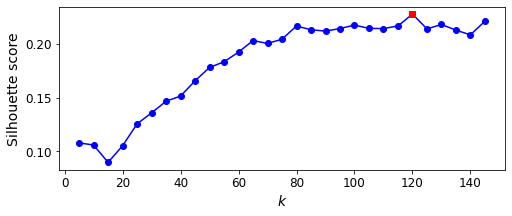

In [ ]:
from sklearn.metrics import silhouette_score

silhouette_scores = [silhouette_score(X_train_pca, model.labels_)
                     for model in kmeans_per_k]
best_index = np.argmax(silhouette_scores)
best_k = k_range[best_index]
best_score = silhouette_scores[best_index]

plt.figure(figsize=(8, 3))
plt.plot(k_range, silhouette_scores, "bo-")
plt.xlabel("$k$", fontsize=14)
plt.ylabel("Silhouette score", fontsize=14)
plt.plot(best_k, best_score, "rs")
plt.show()

In [ ]:
best_k

120

It looks like the best number of clusters is quite high, at 120. You might have expected it to be 40, since there are 40 different people on the pictures. However, the same person may look quite different on different pictures (e.g., with or without glasses, or simply shifted left or right).

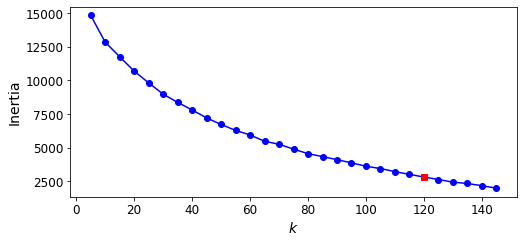

In [ ]:
inertias = [model.inertia_ for model in kmeans_per_k]
best_inertia = inertias[best_index]

plt.figure(figsize=(8, 3.5))
plt.plot(k_range, inertias, "bo-")
plt.xlabel("$k$", fontsize=14)
plt.ylabel("Inertia", fontsize=14)
plt.plot(best_k, best_inertia, "rs")
plt.show()

The optimal number of clusters is not clear on this inertia diagram, as there is no obvious elbow, so let's stick with k=120.

In [ ]:
best_model = kmeans_per_k[best_index]

*Exercise: Visualize the clusters: do you see similar faces in each cluster?*

Cluster 0


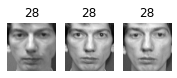

Cluster 1


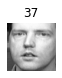

Cluster 2


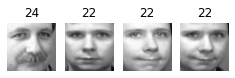

Cluster 3


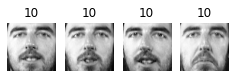

Cluster 4


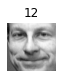

Cluster 5


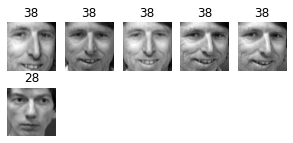

Cluster 6


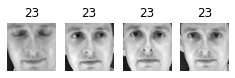

Cluster 7


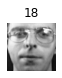

Cluster 8


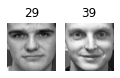

Cluster 9


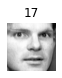

Cluster 10


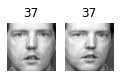

Cluster 11


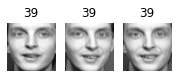

Cluster 12


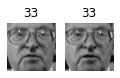

Cluster 13


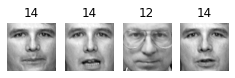

Cluster 14


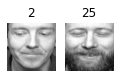

Cluster 15


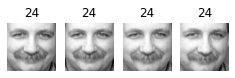

Cluster 16


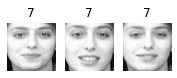

Cluster 17


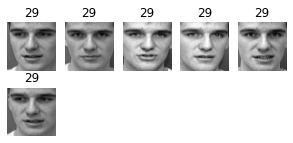

Cluster 18


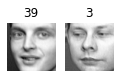

Cluster 19


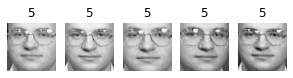

Cluster 20


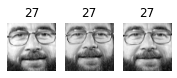

Cluster 21


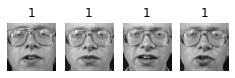

Cluster 22


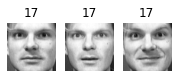

Cluster 23


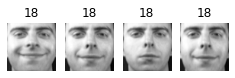

Cluster 24


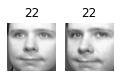

Cluster 25


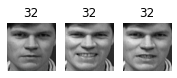

Cluster 26


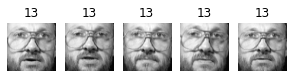

Cluster 27


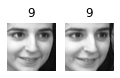

Cluster 28


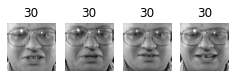

Cluster 29


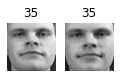

Cluster 30


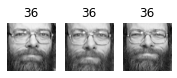

Cluster 31


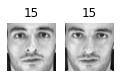

Cluster 32


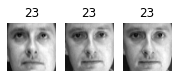

Cluster 33


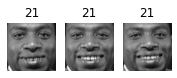

Cluster 34


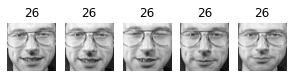

Cluster 35


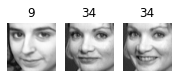

Cluster 36


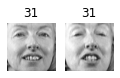

Cluster 37


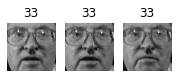

Cluster 38


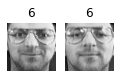

Cluster 39


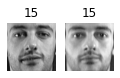

Cluster 40


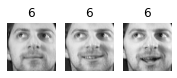

Cluster 41


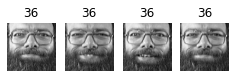

Cluster 42


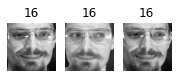

Cluster 43


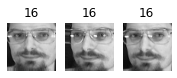

Cluster 44


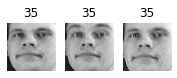

Cluster 45


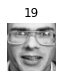

Cluster 46


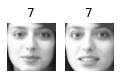

Cluster 47


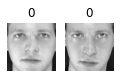

Cluster 48


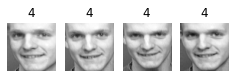

Cluster 49


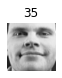

Cluster 50


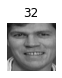

Cluster 51


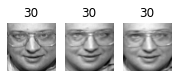

Cluster 52


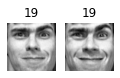

Cluster 53


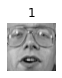

Cluster 54


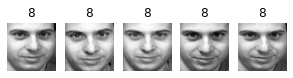

Cluster 55


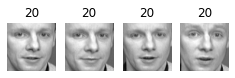

Cluster 56


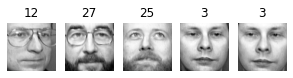

Cluster 57


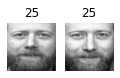

Cluster 58


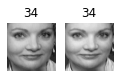

Cluster 59


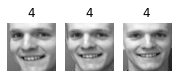

Cluster 60


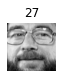

Cluster 61


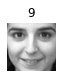

Cluster 62


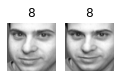

Cluster 63


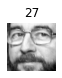

Cluster 64


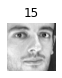

Cluster 65


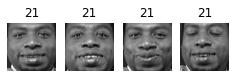

Cluster 66


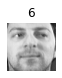

Cluster 67


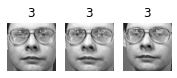

Cluster 68


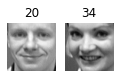

Cluster 69


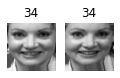

Cluster 70


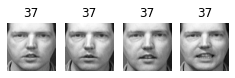

Cluster 71


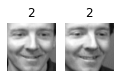

Cluster 72


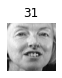

Cluster 73


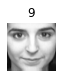

Cluster 74


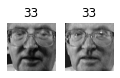

Cluster 75


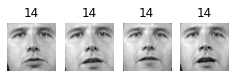

Cluster 76


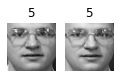

Cluster 77


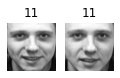

Cluster 78


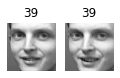

Cluster 79


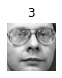

Cluster 80


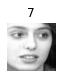

Cluster 81


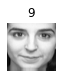

Cluster 82


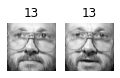

Cluster 83


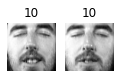

Cluster 84


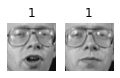

Cluster 85


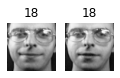

Cluster 86


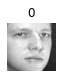

Cluster 87


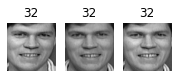

Cluster 88


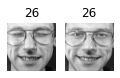

Cluster 89


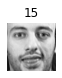

Cluster 90


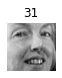

Cluster 91


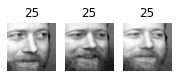

Cluster 92


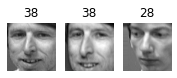

Cluster 93


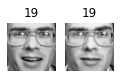

Cluster 94


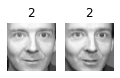

Cluster 95


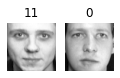

Cluster 96


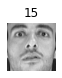

Cluster 97


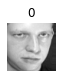

Cluster 98


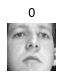

Cluster 99


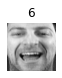

Cluster 100


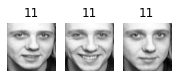

Cluster 101


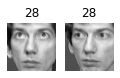

Cluster 102


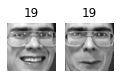

Cluster 103


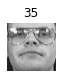

Cluster 104


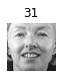

Cluster 105


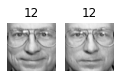

Cluster 106


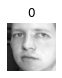

Cluster 107


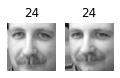

Cluster 108


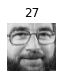

Cluster 109


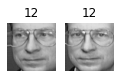

Cluster 110


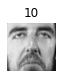

Cluster 111


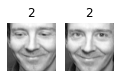

Cluster 112


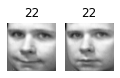

Cluster 113


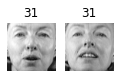

Cluster 114


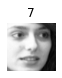

Cluster 115


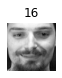

Cluster 116


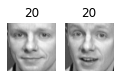

Cluster 117


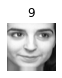

Cluster 118


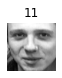

Cluster 119


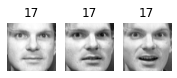

In [ ]:
def plot_faces(faces, labels, n_cols=5):
    n_rows = (len(faces) - 1) // n_cols + 1
    plt.figure(figsize=(n_cols, n_rows * 1.1))
    for index, (face, label) in enumerate(zip(faces, labels)):
        plt.subplot(n_rows, n_cols, index + 1)
        plt.imshow(face.reshape(64, 64), cmap="gray")
        plt.axis("off")
        plt.title(label)
    plt.show()

for cluster_id in np.unique(best_model.labels_):
    print("Cluster", cluster_id)
    in_cluster = best_model.labels_==cluster_id
    faces = X_train[in_cluster].reshape(-1, 64, 64)
    labels = y_train[in_cluster]
    plot_faces(faces, labels)

About 2 out of 3 clusters are useful: that is, they contain at least 2 pictures, all of the same person. However, the rest of the clusters have either one or more intruders, or they have just a single picture.

Clustering images this way may be too imprecise to be directly useful when training a model (as we will see below), but it can be tremendously useful when labeling images in a new dataset: it will usually make labelling much faster.

## 11. Using Clustering as Preprocessing for Classification

*Exercise: Continuing with the Olivetti faces dataset, train a classifier to predict which person is represented in each picture, and evaluate it on the validation set.*

In [ ]:
from sklearn.ensemble import RandomForestClassifier

clf = RandomForestClassifier(n_estimators=150, random_state=42)
clf.fit(X_train_pca, y_train)
clf.score(X_valid_pca, y_valid)

0.9

*Exercise: Next, use K-Means as a dimensionality reduction tool, and train a classifier on the reduced set.*

In [ ]:
X_train_reduced = best_model.transform(X_train_pca)
X_valid_reduced = best_model.transform(X_valid_pca)
X_test_reduced = best_model.transform(X_test_pca)

clf = RandomForestClassifier(n_estimators=150, random_state=42)
clf.fit(X_train_reduced, y_train)
    
clf.score(X_valid_reduced, y_valid)

0.7

Yikes! That's not better at all! Let's see if tuning the number of clusters helps.

*Exercise: Search for the number of clusters that allows the classifier to get the best performance: what performance can you reach?*

We could use a `GridSearchCV` like we did earlier in this notebook, but since we already have a validation set, we don't need K-fold cross-validation, and we're only exploring a single hyperparameter, so it's simpler to just run a loop manually:

In [ ]:
from sklearn.pipeline import Pipeline

for n_clusters in k_range:
    pipeline = Pipeline([
        ("kmeans", KMeans(n_clusters=n_clusters, random_state=n_clusters)),
        ("forest_clf", RandomForestClassifier(n_estimators=150, random_state=42))
    ])
    pipeline.fit(X_train_pca, y_train)
    print(n_clusters, pipeline.score(X_valid_pca, y_valid))

5 0.3625
10 0.55
15 0.6125
20 0.6625
25 0.6625
30 0.7
35 0.6875
40 0.7125
45 0.7
50 0.7375
55 0.7375
60 0.75
65 0.725
70 0.7375
75 0.7875
80 0.7125
85 0.725
90 0.775
95 0.7625
100 0.65
105 0.7125
110 0.725
115 0.7625
120 0.75
125 0.725
130 0.775
135 0.7375
140 0.7375
145 0.725


Oh well, even by tuning the number of clusters, we never get beyond 80% accuracy. Looks like the distances to the cluster centroids are not as informative as the original images.

*Exercise: What if you append the features from the reduced set to the original features (again, searching for the best number of clusters)?*

In [ ]:
X_train_extended = np.c_[X_train_pca, X_train_reduced]
X_valid_extended = np.c_[X_valid_pca, X_valid_reduced]
X_test_extended = np.c_[X_test_pca, X_test_reduced]

In [ ]:
clf = RandomForestClassifier(n_estimators=150, random_state=42)
clf.fit(X_train_extended, y_train)
clf.score(X_valid_extended, y_valid)

0.8125

That's a bit better, but still worse than without the cluster features. The clusters are not useful to directly train a classifier in this case (but they can still help when labelling new training instances).

## 12. A Gaussian Mixture Model for the Olivetti Faces Dataset

*Exercise: Train a Gaussian mixture model on the Olivetti faces dataset. To speed up the algorithm, you should probably reduce the dataset's dimensionality (e.g., use PCA, preserving 99% of the variance).*

In [ ]:
from sklearn.mixture import GaussianMixture

gm = GaussianMixture(n_components=40, random_state=42)
y_pred = gm.fit_predict(X_train_pca)

*Exercise: Use the model to generate some new faces (using the `sample()` method), and visualize them (if you used PCA, you will need to use its `inverse_transform()` method).*

In [ ]:
n_gen_faces = 20
gen_faces_reduced, y_gen_faces = gm.sample(n_samples=n_gen_faces)
gen_faces = pca.inverse_transform(gen_faces_reduced)

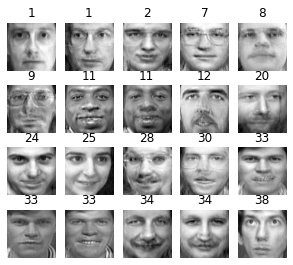

In [ ]:
plot_faces(gen_faces, y_gen_faces)

*Exercise: Try to modify some images (e.g., rotate, flip, darken) and see if the model can detect the anomalies (i.e., compare the output of the `score_samples()` method for normal images and for anomalies).*

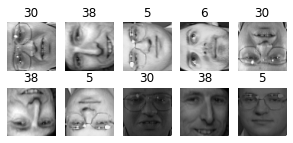

In [ ]:
n_rotated = 4
rotated = np.transpose(X_train[:n_rotated].reshape(-1, 64, 64), axes=[0, 2, 1])
rotated = rotated.reshape(-1, 64*64)
y_rotated = y_train[:n_rotated]

n_flipped = 3
flipped = X_train[:n_flipped].reshape(-1, 64, 64)[:, ::-1]
flipped = flipped.reshape(-1, 64*64)
y_flipped = y_train[:n_flipped]

n_darkened = 3
darkened = X_train[:n_darkened].copy()
darkened[:, 1:-1] *= 0.3
darkened = darkened.reshape(-1, 64*64)
y_darkened = y_train[:n_darkened]

X_bad_faces = np.r_[rotated, flipped, darkened]
y_bad = np.concatenate([y_rotated, y_flipped, y_darkened])

plot_faces(X_bad_faces, y_bad)

In [ ]:
X_bad_faces_pca = pca.transform(X_bad_faces)

In [ ]:
gm.score_samples(X_bad_faces_pca)

array([-2.43643113e+07, -1.89785004e+07, -3.78112493e+07, -4.98187703e+07,
       -3.20479348e+07, -1.37531145e+07, -2.92374053e+07, -1.05489426e+08,
       -1.19575852e+08, -6.74258984e+07])

The bad faces are all considered highly unlikely by the Gaussian Mixture model. Compare this to the scores of some training instances:

In [ ]:
gm.score_samples(X_train_pca[:10])

array([1163.02021069, 1134.03638036, 1156.32132941, 1170.67602788,
       1141.454049  , 1154.35205184, 1091.32894813, 1111.41149521,
       1096.43049182, 1132.98982617])

## 13. Using Dimensionality Reduction Techniques for Anomaly Detection

*Exercise: Some dimensionality reduction techniques can also be used for anomaly detection. For example, take the Olivetti faces dataset and reduce it with PCA, preserving 99% of the variance. Then compute the reconstruction error for each image. Next, take some of the modified images you built in the previous exercise, and look at their reconstruction error: notice how much larger the reconstruction error is. If you plot a reconstructed image, you will see why: it tries to reconstruct a normal face.*

We already reduced the dataset using PCA earlier:

In [ ]:
X_train_pca

array([[ 3.78079963e+00, -1.85479248e+00, -5.14404488e+00, ...,
        -1.35627374e-01, -2.14086145e-01,  6.11920916e-02],
       [ 1.01488419e+01, -1.52754462e+00, -7.66983330e-01, ...,
         1.23931073e-01, -1.35265246e-01, -2.32774969e-02],
       [-1.00152893e+01,  2.87728000e+00, -9.19880748e-01, ...,
         7.26087093e-02, -2.96266354e-03,  1.24891594e-01],
       ...,
       [ 2.47587538e+00,  2.95597076e+00,  1.29985499e+00, ...,
        -2.09109820e-02,  3.48486491e-02, -1.54324114e-01],
       [-3.22031617e+00,  5.34897852e+00,  1.39426768e+00, ...,
         5.75521998e-02, -2.28307784e-01,  1.55577928e-01],
       [-9.22877073e-01, -3.64702868e+00,  2.26087952e+00, ...,
         1.36853799e-01, -6.91265836e-02,  6.26829341e-02]], dtype=float32)

In [ ]:
def reconstruction_errors(pca, X):
    X_pca = pca.transform(X)
    X_reconstructed = pca.inverse_transform(X_pca)
    mse = np.square(X_reconstructed - X).mean(axis=-1)
    return mse

In [ ]:
reconstruction_errors(pca, X_train).mean()

0.0001920535

In [ ]:
reconstruction_errors(pca, X_bad_faces).mean()

0.0047073537

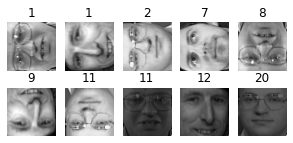

In [ ]:
plot_faces(X_bad_faces, y_gen_faces)

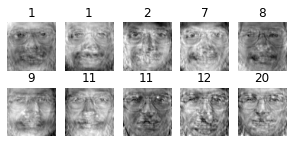

In [ ]:
X_bad_faces_reconstructed = pca.inverse_transform(X_bad_faces_pca)
plot_faces(X_bad_faces_reconstructed, y_gen_faces)